<style>
/* Automatic numbering for report sections when the notebook is rendered. */
body { counter-reset: report-section; }
h2 { counter-reset: report-subsection; }
h2::before {
    counter-increment: report-section;
    content: counter(report-section) ". ";
}
h3::before {
    counter-increment: report-subsection;
    content: counter(report-section) "." counter(report-subsection) " ";
}
</style>

# Human-Caused Wildfire Ignitions in Four Portuguese Municipalities

## Statistical Analysis Before and After the 2017 Wildfire Crisis

This study examines wildfire ignition records from the Sistema de Gestão de Informação de Incêndios Florestais (SGIF), provided by the Instituto da Conservação da Natureza e das Florestas (ICNF).

It focuses on Braga, Guimarães, Guarda, and Faro between 2001 and 2025. The four municipalities represent different geographic, demographic, and territorial contexts in Portugal.

The analysis asks whether the distribution of human-caused ignitions and the annual number of fire ignitions changed after the 2017 wildfire crisis. It distinguishes between negligent and intentional ignitions and uses both descriptive and inferential statistical methods.

## Research questions

### Main research question

Did the distribution of human-caused fire ignitions and the annual number of fire ignitions change significantly before and after the 2017 wildfire crisis in Braga, Guimarães, Guarda, and Faro?

### Specific research questions

#### RQ1: Proportion of intentional ignitions

Did the proportion of intentional ignitions among human-caused ignitions change significantly between the pre-2017 period (2001–2016) and the post-2017 period (2018–2025)?

**Response variable:** Cause type  
**Grouping variable:** Period  
**Statistical test:** Two-proportion test

#### RQ2: Annual number of ignitions

Did the mean annual number of fire ignitions differ significantly between the pre-2017 and post-2017 periods?

**Response variable:** Annual number of ignitions  
**Grouping variable:** Period  
**Statistical test:** Independent-samples t-test

#### RQ3: Differences between municipalities

Did the mean annual number of fire ignitions differ significantly among Braga, Guimarães, Guarda, and Faro?

**Response variable:** Annual number of ignitions  
**Grouping variable:** Municipality  
**Statistical test:** One-way ANOVA

All hypothesis tests use a significance level of \(\alpha = 0.05\). The year 2017 is treated as a transition year and excluded from the before-and-after comparisons.

## Data and study scope

The dataset contains individual wildfire ignition records from the SGIF/ICNF database. The available files cover the period from 2001 to 2025.

The files are read and combined into a single dataset for the analysis of Braga, Guimarães, Guarda, and Faro. Municipality names are normalized so that differences in spelling and accents do not affect the selection.

### Imports and analysis parameters

Column names are converted to uppercase, which ensures consistent processing across files from different years.

In [78]:
from pathlib import Path
import pandas as pd

DATA_FOLDER = Path("dados")
MUNICIPALITIES = ["BRAGA", "GUIMARAES", "GUARDA", "FARO"]

MUNICIPALITIES_AREA_KM2 = {
    "BRAGA": 183,
    "GUIMARAES": 241,
    "GUARDA": 712,
    "FARO": 203,
}



### Loading and combining the data

The CSV and Excel files are located in the `dados` folder. Each file is read separately, its column names are standardized, and the resulting tables are concatenated into a single dataset.

The output below gives the number of records and the available variables before the study scope is applied.

In [79]:

files = sorted(
    file
    for extension in ("csv",)
    for file in DATA_FOLDER.glob(f"*.{extension}")
)

if not files:
    raise FileNotFoundError(f"No files found in folder '{DATA_FOLDER}'.")

tables = []

for file in files:
    print("Reading:", file)

    if file.suffix.lower() == ".csv":
        table = pd.read_csv(
            file,
            sep=";",
            decimal=",",
            encoding="utf-8-sig",
            low_memory=False
        )
    else:
        table = pd.read_excel(file)

    table.columns = table.columns.astype(str).str.upper().str.strip()
    tables.append(table)

df = pd.concat(tables, ignore_index=True)

print(f"Total records: {len(df)}")
print("Columns:", sorted(list(df.columns)))


Reading: dados/Registos_Incendios_SGIF_2001_2010.csv
Reading: dados/Registos_Incendios_SGIF_2011_2020.csv
Reading: dados/Registos_Incendios_SGIF_2021_2025.csv
Total records: 497478
Columns: ['ANO', 'AREAAGRIC_HA', 'AREAMATO_HA', 'AREAPOV_HA', 'AREATOTAL_HA', 'BUI', 'CLASSEAREA', 'CODCAUSA', 'CODIGO_ANEPC', 'CODIGO_SGIF', 'CONCELHO', 'DATAHORAALERTA', 'DATAHORA_EXTINCAO', 'DATAHORA_PRIMEIRAINTERVENCAO', 'DC', 'DESCRICAOCAUSA', 'DIA', 'DISTRITO', 'DMC', 'DSR', 'DTCCFR', 'DURACAO_HORAS', 'FFMC', 'FONTEALERTA', 'FREGUESIA', 'FWI', 'GRUPOCAUSA', 'HORA', 'INCSUP24HORAS', 'ISI', 'LATITUDE', 'LOCAL', 'LONGITUDE', 'MES', 'RNAP', 'RNMPF', 'TIPOCAUSA', 'X_ETRS89', 'X_MILITAR', 'Y_ETRS89', 'Y_MILITAR']


### Defining the study population

Municipality names are converted to uppercase, whitespace is removed, and accented characters are normalized. The resulting identifier is used to select the four municipalities included in the study.

The dataset is then restricted to Braga, Guimarães, Guarda, and Faro.

In [80]:
# Standardize municipality names by converting to uppercase, trimming spaces,
# and removing accents/special characters to create a consistent matching key.
df["MUNICIPALITY"] = (
    df["CONCELHO"].astype(str).str.upper().str.strip()
    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
)

# Identify the municipality whose normalized versions
# match the reference municipality scope and display each unique matches.
matching_spellings = df.loc[
    df["MUNICIPALITY"].isin(MUNICIPALITIES),
    "CONCELHO"
].unique()
print("Matching spellings:", matching_spellings)


# Filter records belonging to the municipalities scope
# and create an independent copy of the resulting subset.
scoped_data = df[df["MUNICIPALITY"].isin(MUNICIPALITIES)].copy()
print(f"Records in scope: {len(scoped_data)}")


Matching spellings: ['Guimarães' 'Guarda' 'Braga' 'Faro']
Records in scope: 15534


### Defining the analysis year

For each ignition, the analysis year is taken from the alert date whenever possible. If the alert date is unavailable or cannot be used, the original `ANO` variable provides the year.

This common year variable is used to define the periods for the statistical comparisons.

In [81]:
# Create a unified year variable from the alert date when available;
# otherwise, use the existing year column.
if "DATAHORAALERTA" in scoped_data.columns:
    scoped_data["ANALYSIS_YEAR"] = pd.to_datetime(
        scoped_data["DATAHORAALERTA"], errors="coerce", dayfirst=True
    ).dt.year
else:
    scoped_data["ANALYSIS_YEAR"] = scoped_data["ANO"]


# Preview the municipality and analysis year fields.
scoped_data[
    [
        "MUNICIPALITY",
        "ANALYSIS_YEAR"
    ]
].head() #.head() #.tail()

,MUNICIPALITY,ANALYSIS_YEAR
104,GUIMARAES,2001
117,GUIMARAES,2001
127,GUIMARAES,2001
128,GUARDA,2001
165,GUIMARAES,2001


### Normalizing ignition causes

Cause values are converted to uppercase. In the SGIF data, an empty cause field means the fire was **not investigated**, while `DESCONHECIDA` means it was investigated but the cause could not be determined.

Since the research questions focus only on human-caused ignitions (negligent vs. intentional), both situations are grouped into a single category, `DESCONHECIDA`, and flagged with `MISSING_CAUSE`. These records are excluded from the cause comparison but kept in the dataset and reported, because removing them silently could bias the analysis.

In [82]:
# Clean and standardize cause descriptions, flag missing values,
# and assign a default label to records without cause information.
cause = (
    scoped_data["TIPOCAUSA"].astype(str).str.strip()
    .replace({"": None, "nan": None, "None": None})
)
scoped_data["CAUSE"] = cause.fillna("DESCONHECIDA").str.upper()
scoped_data["MISSING_CAUSE"] = scoped_data["CAUSE"].eq("DESCONHECIDA")

# Preview the original, normalized, and missing-cause indicators.
scoped_data[
    [
        "TIPOCAUSA",
        "CAUSE",
        "MISSING_CAUSE"
    ]
].head()

,TIPOCAUSA,CAUSE,MISSING_CAUSE
104,NaN,DESCONHECIDA,True
117,NaN,DESCONHECIDA,True
127,NaN,DESCONHECIDA,True
128,NaN,DESCONHECIDA,True
165,NaN,DESCONHECIDA,True


### Creating derived variables

The analysis uses two derived variables:

- `INTERVENTION_TIME_MINUTES`: time between the alert and the first intervention;
- `PERIOD`: temporal classification of each record.

| Period | Years | Role in the analysis |
|---|---:|---|
| Pre-2017 | 2001–2016 | Before the wildfire crisis |
| 2017 | 2017 | Transition year, excluded from comparisons |
| Post-2017 | 2018–2025 | After the wildfire crisis |

Ignition density is calculated from the area of each municipality so that comparisons account for differences in municipality size.

In [83]:
alert_time = pd.to_datetime(scoped_data["DATAHORAALERTA"], errors="coerce", dayfirst=True)
intervention_time = pd.to_datetime(
    scoped_data["DATAHORA_PRIMEIRAINTERVENCAO"], errors="coerce", dayfirst=True
)
scoped_data["INTERVENTION_TIME_MINUTES"] = (intervention_time - alert_time).dt.total_seconds() / 60

scoped_data["PERIOD"] = pd.cut(
    scoped_data["ANALYSIS_YEAR"], bins=[2000, 2016, 2017, 2025],
    labels=["2001-2016", "2017", "2018-2025"]
)

scoped_data[["ANALYSIS_YEAR", "INTERVENTION_TIME_MINUTES", "PERIOD"]].head()

,ANALYSIS_YEAR,INTERVENTION_TIME_MINUTES,PERIOD
104,2001,NaN,2001-2016
117,2001,NaN,2001-2016
127,2001,NaN,2001-2016
128,2001,NaN,2001-2016
165,2001,NaN,2001-2016


In [84]:
# Calculate the ignition density for a given scope of data.
# This function takes a DataFrame of ignition data and calculates
# the density of ignitions per square kilometer per year for each municipality.
def calculate_ignition_density(
    data,
    start_year=None,
    end_year=None,
    municipalities=MUNICIPALITIES,
    area_by_municipality=MUNICIPALITIES_AREA_KM2,
    year_column="ANALYSIS_YEAR",
):
    scoped = data.copy()

    if start_year is not None:
        scoped = scoped[scoped[year_column] >= start_year]

    if end_year is not None:
        scoped = scoped[scoped[year_column] <= end_year]

    years_in_scope = scoped[year_column].dropna().nunique()

    if years_in_scope == 0:
        raise ValueError("The selected scope contains no valid years.")

    result = (
        scoped.groupby("MUNICIPALITY")
        .size()
        .rename("IGNITIONS")
        .reindex(municipalities, fill_value=0)
        .to_frame()
    )

    result["AREA_KM2"] = result.index.map(area_by_municipality)
    result["YEARS"] = years_in_scope
    result["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"] = (
        result["IGNITIONS"]
        / result["AREA_KM2"]
        / result["YEARS"]
    )

    return result.reset_index()

In [85]:
# All years
ignition_density = calculate_ignition_density(scoped_data)
display(ignition_density)

,MUNICIPALITY,IGNITIONS,AREA_KM2,YEARS,IGNITION_DENSITY_IGNITIONS_KM2_YEAR
0,BRAGA,4279,183,25,0.935301
1,GUIMARAES,8641,241,25,1.434191
2,GUARDA,1806,712,25,0.101461
3,FARO,808,203,25,0.159212


In [86]:
required_columns = [
    "MUNICIPALITY",                  # normalized municipality name
    "PERIOD",                        # period category based on analysis year
    "ANALYSIS_YEAR",                 # analysis year
    "DATAHORAALERTA",                # alert date and time
    "DATAHORA_PRIMEIRAINTERVENCAO",  # first intervention date and time
    "DATAHORA_EXTINCAO",             # extinction date and time
    "CAUSE",                         # normalized cause description
    "MISSING_CAUSE",                 # no cause attributed (empty or unknown)
    "AREATOTAL_HA",                  # total burned area in hectares
    "INTERVENTION_TIME_MINUTES",     # time to first intervention (minutes)
    "DURACAO_HORAS",                 # fire duration in hours
]

missing_columns = [
    column for column in required_columns
    if column not in scoped_data.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

scoped_data = scoped_data[required_columns].copy()

print(f"Filtered data shape: {scoped_data.shape}")
display(scoped_data.head())

Filtered data shape: (15534, 11)


,MUNICIPALITY,PERIOD,ANALYSIS_YEAR,DATAHORAALERTA,DATAHORA_PRIMEIRAINTERVENCAO,DATAHORA_EXTINCAO,CAUSE,MISSING_CAUSE,AREATOTAL_HA,INTERVENTION_TIME_MINUTES,DURACAO_HORAS
104,GUIMARAES,2001-2016,2001,18/02/2001 22:31,NaN,18/02/2001 23:32,DESCONHECIDA,True,0.10,NaN,1.016667
117,GUIMARAES,2001-2016,2001,19/02/2001 14:48,NaN,19/02/2001 16:05,DESCONHECIDA,True,0.20,NaN,1.283333
127,GUIMARAES,2001-2016,2001,19/02/2001 17:53,NaN,19/02/2001 18:45,DESCONHECIDA,True,3.00,NaN,0.866667
128,GUARDA,2001-2016,2001,19/02/2001 17:55,NaN,19/02/2001 18:40,DESCONHECIDA,True,1.00,NaN,0.750000
165,GUIMARAES,2001-2016,2001,20/02/2001 17:33,NaN,20/02/2001 18:30,DESCONHECIDA,True,0.15,NaN,0.950000


In [87]:
# Uncomment the following lines to save the scoped data to a CSV file.
# output_file =  "scoped_data_required_columns.csv"
#
# scoped_data.to_csv(
#    output_file,
#    index=False,
#    encoding="utf-8-sig"
# )
#
# print(f"Saved {len(scoped_data):,} records to: {output_file}")

## Data quality and descriptive verification

The tables below check the structure and quality of the scoped dataset. They include annual ignition counts, cause categories, missing-cause percentages, missing quantitative values, intervention times, and the contingency table used to compare negligent and intentional ignitions.

These checks are carried out before the inferential statistical analysis.

In [88]:
print("1) Records by year and municipality")
display(pd.crosstab(scoped_data["ANALYSIS_YEAR"], scoped_data["MUNICIPALITY"]))

1) Records by year and municipality


MUNICIPALITY,BRAGA,FARO,GUARDA,GUIMARAES
ANALYSIS_YEAR,,,,
2001,285,16,159,833
2002,279,15,154,795
2003,381,14,122,950
2004,253,27,74,593
2005,406,29,137,876
2006,330,69,102,434
2007,216,80,84,383
2008,83,42,142,170
2009,242,61,109,487


In [89]:
print("2) Cause type by municipality")
display(pd.crosstab(scoped_data["CAUSE"], scoped_data["MUNICIPALITY"]))


2) Cause type by municipality


MUNICIPALITY,BRAGA,FARO,GUARDA,GUIMARAES
CAUSE,,,,
DESCONHECIDA,3687,513,823,7910
INTENCIONAL,146,42,230,202
NATURAL,0,0,50,0
NEGLIGENTE,168,248,635,369
REACENDIMENTO,278,5,68,160


In [90]:
print("3) % of records without a cause, by year and municipality")
display((pd.crosstab(
    scoped_data["ANALYSIS_YEAR"], scoped_data["MUNICIPALITY"], values=scoped_data["MISSING_CAUSE"], aggfunc="mean"
) * 100).round(1))


3) % of records without a cause, by year and municipality


MUNICIPALITY,BRAGA,FARO,GUARDA,GUIMARAES
ANALYSIS_YEAR,,,,
2001,98.9,100.0,100.0,99.9
2002,98.9,73.3,90.3,99.9
2003,99.2,100.0,89.3,99.8
2004,99.6,88.9,89.2,99.5
2005,97.5,100.0,94.9,99.2
2006,99.7,98.6,83.3,99.8
2007,90.7,96.2,48.8,98.4
2008,98.8,90.5,25.4,96.5
2009,87.6,95.1,12.8,98.8


In [91]:
columns = [
    "AREATOTAL_HA", "DATAHORAALERTA",
    "DATAHORA_PRIMEIRAINTERVENCAO", "DATAHORA_EXTINCAO", "DURACAO_HORAS",
]
columns = [column for column in columns if column in scoped_data.columns]

print("4) % missing by year")
display((scoped_data.groupby("ANALYSIS_YEAR")[columns].apply(lambda x: x.isna().mean()) * 100).round(1))


4) % missing by year


,AREATOTAL_HA,DATAHORAALERTA,DATAHORA_PRIMEIRAINTERVENCAO,DATAHORA_EXTINCAO,DURACAO_HORAS
ANALYSIS_YEAR,,,,,
2001,0.0,0.0,100.0,0.0,0.0
2002,0.0,0.0,100.0,0.0,0.0
2003,0.0,0.0,100.0,0.0,0.0
2004,0.0,0.0,100.0,0.0,0.0
2005,0.0,0.0,100.0,0.0,0.0
2006,0.0,0.0,100.0,0.0,0.0
2007,0.0,0.0,100.0,0.0,0.0
2008,0.0,0.0,17.8,0.0,0.0
2009,0.0,0.0,12.3,0.0,0.0


In [92]:
print("5) Time to first intervention (minutes)")
display(scoped_data.groupby("MUNICIPALITY")["INTERVENTION_TIME_MINUTES"].describe().round(1))
print("Negative:", int((scoped_data["INTERVENTION_TIME_MINUTES"] < 0).sum()),
      "| Above 24h:", int((scoped_data["INTERVENTION_TIME_MINUTES"] > 1440).sum()))


5) Time to first intervention (minutes)


,count,mean,std,min,25%,50%,75%,max
MUNICIPALITY,,,,,,,,
BRAGA,2068.0,12.1,7.8,0.0,8.0,11.0,15.0,139.0
FARO,550.0,10.4,5.0,1.0,7.0,10.0,12.0,42.0
GUARDA,915.0,16.2,15.8,0.0,9.0,13.0,20.0,265.0
GUIMARAES,3671.0,12.1,13.4,0.0,7.0,10.0,15.0,615.0


Negative: 0 | Above 24h: 0


In [93]:

hypothesis_data = scoped_data[
    scoped_data["CAUSE"].str.lower().isin(["negligente", "intencional"])
    & (scoped_data["PERIOD"] != "2017")
]
print("6) Negligent vs intentional by period (2017 excluded)")
display(pd.crosstab([hypothesis_data["MUNICIPALITY"], hypothesis_data["PERIOD"]], hypothesis_data["CAUSE"]))


6) Negligent vs intentional by period (2017 excluded)


CAUSE                   INTENCIONAL  NEGLIGENTE
MUNICIPALITY PERIOD                            
BRAGA        2001-2016           60         113
             2018-2025           85          48
FARO         2001-2016            9         113
             2018-2025           33         117
GUARDA       2001-2016          137         454
             2018-2025           66         147
GUIMARAES    2001-2016           35         145
             2018-2025          167         221

## Summary of the data preparation stage

The prepared dataset contains:

- Records from the four selected municipalities;
- A standardized analysis year;
- A categorical period variable;
- Normalized ignition-cause categories;
- An indicator for missing cause information;
- Annual ignition counts;
- Ignition density by municipality;
- Intervention-time measurements.

These variables provide the basis for the exploratory analysis and for testing the three research questions defined above.

# Exploring the Data

This exploratory analysis characterizes the wildfire ignition records before the inferential stage. Its purpose is to describe the main features of the data, identify potential differences between the two periods, and provide descriptive evidence to guide the investigation of the research questions.

Two qualitative variables are analyzed in this section:

1. **Municipality.** Identifies the municipality where the ignition occurred. The study covers Braga, Guimarães, Guarda, and Faro.
2. **Cause type.** Identifies the recorded cause of the ignition. The composition charts compare every recorded cause category across periods, with particular attention to intentional and negligent ignitions, the two categories relevant to RQ1.

Four quantitative variables are analyzed in the subsequent section:

1. **Total burned area (ha).** Total area burned by each ignition, measured in hectares.
2. **Intervention time (minutes).** Elapsed time between the alert and the first intervention.
3. **Duration (hours).** Total duration of the fire, measured in hours.
4. **Ignition density (ignitions/km²/year).** Annual number of ignitions relative to the municipality's geographical area.

The descriptive comparisons use two periods:

- **Pre-2017:** 2001–2016.
- **Post-2017:** 2018–2025.

The year 2017 is treated as a transition year and is excluded from all before-and-after comparisons. The qualitative analysis first examines the distribution of ignitions across municipalities and then compares the relative composition of intentional and negligent causes.

The code cell below defines the shared color and formatting conventions used throughout the exploratory analysis; the same conventions will be reused for the quantitative variables.


In [94]:
# Shared settings for the exploratory analysis.

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

# Fixed period colors and labels. These are reused in every period comparison.
COMPARISON_PERIODS = ["2001-2016", "2018-2025"]
PERIOD_LABELS = {"2001-2016": "2001–2016", "2018-2025": "2018–2025"}
PERIOD_COLORS = {"2001-2016": "#1F4E79", "2018-2025": "#E69F00"}

# Fixed cause order, colors, and labels. All recorded cause categories are shown.
CAUSE_COMPARISON = [
    "INTENCIONAL",
    "NEGLIGENTE",
    "REACENDIMENTO",
    "NATURAL",
    "DESCONHECIDA",
]
CAUSE_LABELS = {
    "INTENCIONAL": "Intentional",
    "NEGLIGENTE": "Negligent",
    "REACENDIMENTO": "Reignition",
    "NATURAL": "Natural",
    "DESCONHECIDA": "Unknown",
}
CAUSE_COLORS = {
    "INTENCIONAL": "#B2182B",
    "NEGLIGENTE": "#4D4D4D",
    "REACENDIMENTO": "#8073AC",
    "NATURAL": "#1B9E77",
    "DESCONHECIDA": "#8C8C8C",
}
CAUSE_TEXT_COLORS = {"DESCONHECIDA": "#1A1A1A"}
CAUSE_LABEL_MIN_PERCENT = 2.5

# Municipality order, display labels, and colors.
MUNICIPALITY_LABELS = {
    "BRAGA": "Braga",
    "GUIMARAES": "Guimarães",
    "GUARDA": "Guarda",
    "FARO": "Faro",
}
MUNICIPALITY_COLORS = {
    "BRAGA": "#1B9E77",
    "GUIMARAES": "#7570B3",
    "GUARDA": "#D95F02",
    "FARO": "#E7298A",
}
MUNICIPALITY_LINESTYLES = {
    "BRAGA": "-",
    "GUIMARAES": "--",
    "GUARDA": "-.",
    "FARO": ":",
}
MUNICIPALITY_MARKERS = {
    "BRAGA": "o",
    "GUIMARAES": "s",
    "GUARDA": "^",
    "FARO": "D",
}

# Consistent academic figure style.
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})


def format_categorical_description(series, variable_name):
    """Return a readable one-variable description with two-decimal numbers."""
    summary = series.describe(include="all").to_frame(name=variable_name)
    summary = summary.rename(index={
        "count": "Count",
        "unique": "Unique values",
        "top": "Most frequent category",
        "freq": "Frequency",
    })
    summary[variable_name] = summary[variable_name].map(
        lambda value: f"{value:.2f}" if pd.api.types.is_number(value) else value
    )
    summary.index.name = "Statistic"
    return summary


# The exploratory plots require complete keys; fail explicitly if any are missing.
if scoped_data[["MUNICIPALITY", "PERIOD", "CAUSE"]].isna().any().any():
    raise ValueError(
        "The scoped dataset contains missing municipality, period, or cause values."
    )


## Municipality

Municipality is the territorial unit of the analysis. The description below summarizes the distribution of the in-scope ignition records across the four municipalities.


### Descriptive statistics

The table reports the output of `scoped_data["MUNICIPALITY"].describe(include="all")`, with numerical values rounded to two decimal places.


In [95]:
municipality_description = format_categorical_description(
    scoped_data["MUNICIPALITY"], "MUNICIPALITY"
)
display(municipality_description)


,MUNICIPALITY
Statistic,
Count,15534.00
Unique values,4.00
Most frequent category,GUIMARAES
Frequency,8641.00


### Total ignitions by municipality and period

The grouped bars compare the total number of recorded ignitions in each municipality between the two periods. The full in-scope ignition population is used, not only records with a known cause.


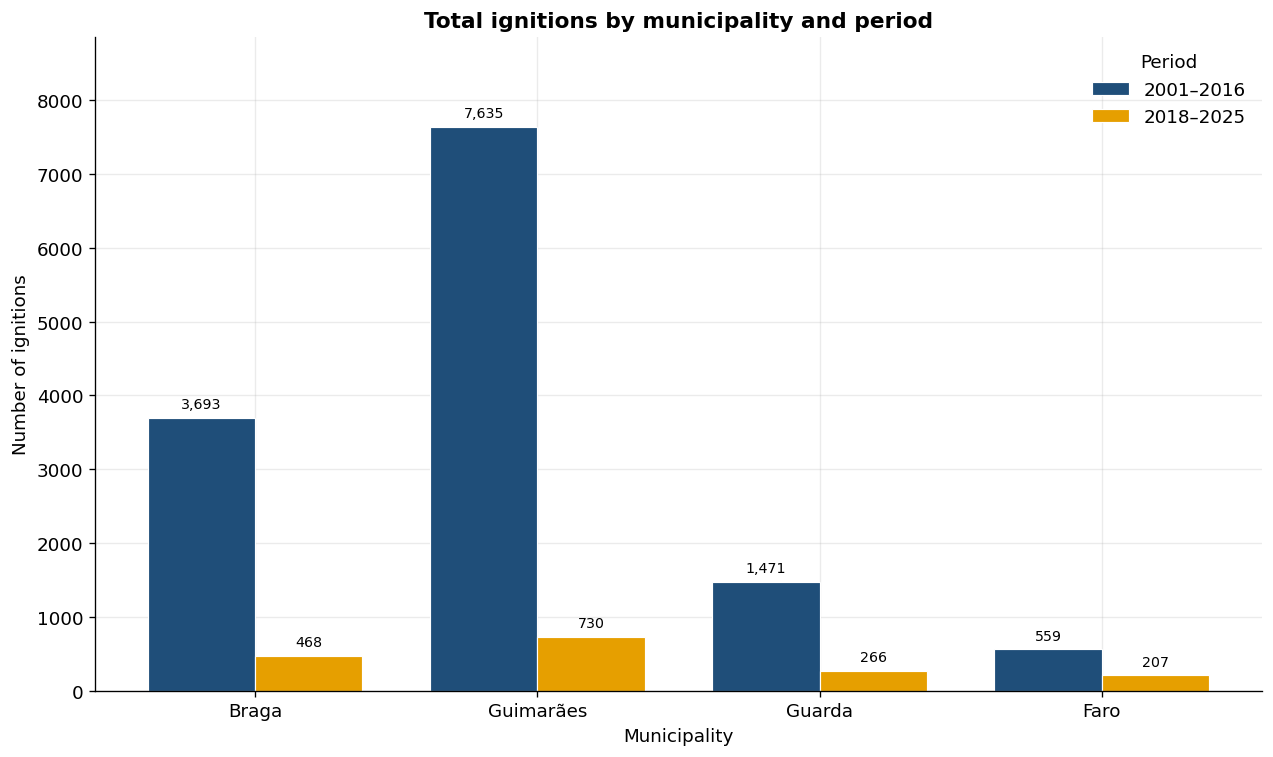

In [96]:
# Count all in-scope ignitions by municipality and comparison period.
municipality_period_counts = (
    scoped_data.loc[scoped_data["PERIOD"].isin(COMPARISON_PERIODS)]
    .groupby(["MUNICIPALITY", "PERIOD"], observed=True)
    .size()
    .rename("IGNITIONS")
    .reindex(
        pd.MultiIndex.from_product(
            [MUNICIPALITIES, COMPARISON_PERIODS],
            names=["MUNICIPALITY", "PERIOD"],
        ),
        fill_value=0,
    )
    .reset_index()
)

if set(municipality_period_counts["MUNICIPALITY"]) != set(MUNICIPALITIES):
    raise ValueError("The municipality summary does not contain all four municipalities.")
if set(municipality_period_counts["PERIOD"]) != set(COMPARISON_PERIODS):
    raise ValueError("The municipality summary contains periods outside the comparison.")

municipality_counts = (
    municipality_period_counts
    .pivot(index="MUNICIPALITY", columns="PERIOD", values="IGNITIONS")
    .reindex(index=MUNICIPALITIES, columns=COMPARISON_PERIODS)
)

fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
positions = list(range(len(MUNICIPALITIES)))
bar_width = 0.38
max_count = municipality_counts.to_numpy().max()

for i, period in enumerate(COMPARISON_PERIODS):
    offset = (i - 0.5) * bar_width
    bar_positions = [position + offset for position in positions]
    bars = ax.bar(
        bar_positions,
        municipality_counts[period],
        width=bar_width,
        color=PERIOD_COLORS[period],
        edgecolor="white",
        linewidth=0.7,
        label=PERIOD_LABELS[period],
    )
    for bar, value in zip(bars, municipality_counts[period]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max_count * 0.012,
            f"{int(value):,}",
            ha="center",
            va="bottom",
            fontsize=8.5,
        )

ax.set_xticks(positions)
ax.set_xticklabels([MUNICIPALITY_LABELS[m] for m in MUNICIPALITIES])
ax.set_xlabel("Municipality")
ax.set_ylabel("Number of ignitions")
ax.set_title("Total ignitions by municipality and period")
ax.set_ylim(0, max_count * 1.16)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Period", loc="upper right")
plt.show()
plt.close(fig)


**NOTE:** Counts include all in-scope ignition records in the four municipalities. The 2017 transition year is excluded from both periods, and the number above each bar is the number of ignitions represented by that bar.


### Annual ignition frequency by municipality

The annual series provide an alternative view of the same variable. They show how the number of ignitions varied from year to year within each municipality, rather than only the aggregate totals for each period.


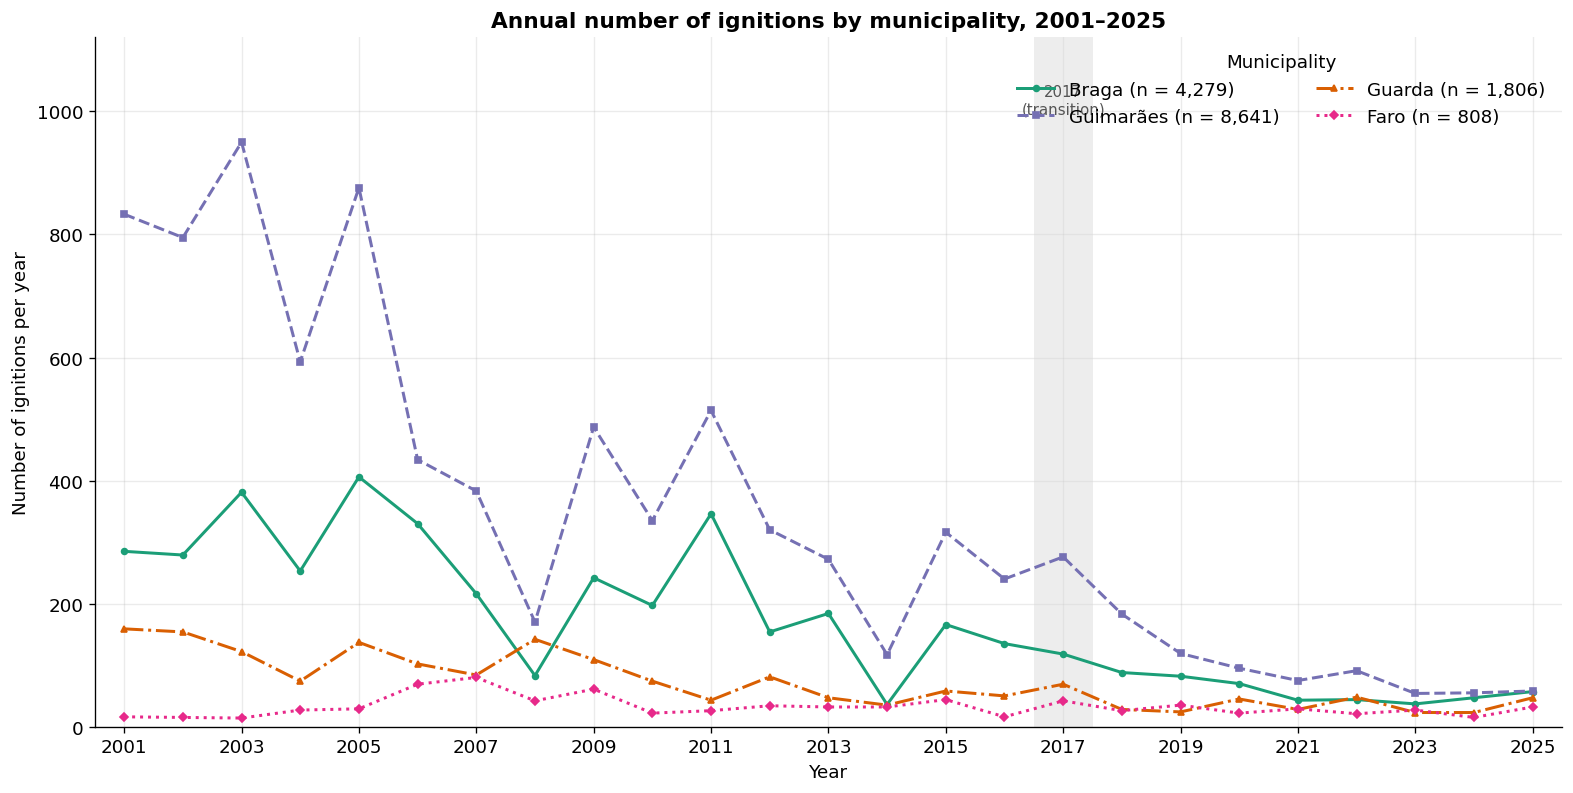

In [97]:
# Build a complete annual series from 2001 to 2025, including the 2017 transition year.
analysis_periods = COMPARISON_PERIODS + ["2017"]
year_min = int(
    scoped_data.loc[scoped_data["PERIOD"].isin(analysis_periods), "ANALYSIS_YEAR"].min()
)
year_max = int(
    scoped_data.loc[scoped_data["PERIOD"].isin(analysis_periods), "ANALYSIS_YEAR"].max()
)
all_years = list(range(year_min, year_max + 1))

annual_counts = (
    scoped_data.loc[scoped_data["PERIOD"].isin(analysis_periods)]
    .groupby(["MUNICIPALITY", "ANALYSIS_YEAR"], observed=True)
    .size()
    .rename("IGNITIONS")
    .reindex(
        pd.MultiIndex.from_product(
            [MUNICIPALITIES, all_years],
            names=["MUNICIPALITY", "ANALYSIS_YEAR"],
        ),
        fill_value=0,
    )
    .reset_index()
)

annual_series = (
    annual_counts
    .pivot(index="ANALYSIS_YEAR", columns="MUNICIPALITY", values="IGNITIONS")
    .reindex(index=all_years, columns=MUNICIPALITIES)
)
municipality_totals = (
    scoped_data.loc[scoped_data["PERIOD"].isin(analysis_periods)]
    .groupby("MUNICIPALITY")
    .size()
    .reindex(MUNICIPALITIES, fill_value=0)
)

fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)
for municipality in MUNICIPALITIES:
    ax.plot(
        annual_series.index,
        annual_series[municipality],
        color=MUNICIPALITY_COLORS[municipality],
        linestyle=MUNICIPALITY_LINESTYLES[municipality],
        marker=MUNICIPALITY_MARKERS[municipality],
        markersize=3.5,
        linewidth=1.8,
        label=(
            f"{MUNICIPALITY_LABELS[municipality]} "
            f"(n = {int(municipality_totals[municipality]):,})"
        ),
    )

annual_max = annual_series.max().max()
ax.axvspan(2016.5, 2017.5, color="#D9D9D9", alpha=0.45, linewidth=0)
ax.text(
    2017,
    annual_max * 1.10,
    "2017\n(transition)",
    ha="center",
    va="top",
    fontsize=9,
    color="#555555",
)
ax.set_xticks(list(range(year_min, year_max + 1, 2)))
ax.set_xlim(year_min - 0.5, year_max + 0.5)
ax.set_ylim(0, annual_max * 1.18)
ax.set_xlabel("Year")
ax.set_ylabel("Number of ignitions per year")
ax.set_title("Annual number of ignitions by municipality, 2001–2025")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Municipality", loc="upper right", ncol=2)
plt.show()
plt.close(fig)


**NOTE:** The annual series include 2017, so the line for each municipality is continuous from 2001 to 2025. The grey band marks 2017 as the transition year. Legend totals give the number of ignitions per municipality from 2001 to 2025; each point in the plot is an annual count.

MUNICIPALITY CONCLUSIONS:


## Cause Type

Cause type is the qualitative variable used in RQ1. The full cause distribution is described first. The composition charts then compare all recorded cause categories across periods, while intentional and negligent ignitions remain the two categories of primary interest for the research question.


### Descriptive statistics

The table reports the output of `scoped_data["CAUSE"].describe(include="all")`, with numerical values rounded to two decimal places.


In [98]:
cause_description = format_categorical_description(scoped_data["CAUSE"], "CAUSE")
display(cause_description)


,CAUSE
Statistic,
Count,15534.00
Unique values,5.00
Most frequent category,DESCONHECIDA
Frequency,12933.00


**NOTE:** `DESCONHECIDA` combines records whose cause field is empty (not investigated) with records that were investigated but classified as unknown. All five recorded cause categories — `INTENCIONAL`, `NEGLIGENTE`, `REACENDIMENTO`, `NATURAL`, and `DESCONHECIDA` — are retained in the composition analysis below, so the bars and heatmaps describe the full recorded cause composition rather than only the intentional-versus-negligent subset.


### Relative composition of ignition causes

The comparison uses all records in the canonical dataset whose period is either 2001–2016 or 2018–2025, retaining every recorded cause category (`INTENCIONAL`, `NEGLIGENTE`, `REACENDIMENTO`, `NATURAL`, and `DESCONHECIDA`). The canonical dataset is not modified.

Within each municipality and period, the proportion for each cause is calculated as:

\[
\text{Cause proportion} =
\frac{\text{Number of ignitions with that cause}}{\text{Total number of recorded ignitions in the municipality-period}}
\]

The denominator is therefore the total number of recorded ignitions in that municipality and period, and the five cause proportions sum to 100%.


In [99]:
# Derived dataset for the cause composition. The canonical scoped_data is not modified.
cause_comparison_data = scoped_data.loc[
    scoped_data["PERIOD"].isin(COMPARISON_PERIODS)
].copy()

if cause_comparison_data[["MUNICIPALITY", "PERIOD", "CAUSE"]].isna().any().any():
    raise ValueError("The cause-comparison subset contains missing key values.")
if (cause_comparison_data["PERIOD"].astype(str) == "2017").any():
    raise ValueError("The 2017 transition year must be excluded from the cause comparison.")
if set(cause_comparison_data["MUNICIPALITY"]) != set(MUNICIPALITIES):
    raise ValueError("The cause-comparison subset does not contain all four municipalities.")
unexpected_causes = set(cause_comparison_data["CAUSE"]) - set(CAUSE_COMPARISON)
if unexpected_causes:
    raise ValueError(f"Unexpected cause categories were found: {sorted(unexpected_causes)}")

# Complete municipality-period-cause grid, preserving the fixed ordering.
cause_counts = (
    cause_comparison_data
    .groupby(["MUNICIPALITY", "PERIOD", "CAUSE"], observed=True)
    .size()
    .rename("IGNITIONS")
    .reindex(
        pd.MultiIndex.from_product(
            [MUNICIPALITIES, COMPARISON_PERIODS, CAUSE_COMPARISON],
            names=["MUNICIPALITY", "PERIOD", "CAUSE"],
        ),
        fill_value=0,
    )
    .reset_index()
)
cause_counts["TOTAL"] = (
    cause_counts.groupby(["MUNICIPALITY", "PERIOD"])["IGNITIONS"].transform("sum")
)
if (cause_counts["TOTAL"] == 0).any():
    raise ValueError("At least one municipality-period has no recorded ignitions.")
cause_counts["PROPORTION"] = cause_counts["IGNITIONS"] / cause_counts["TOTAL"]

proportion_sums = cause_counts.groupby(["MUNICIPALITY", "PERIOD"])["PROPORTION"].sum()
if (proportion_sums - 1).abs().max() > 1e-9:
    raise ValueError("Cause proportions do not sum to 100% within each municipality-period.")

print(
    f"Cause-comparison subset: {len(cause_comparison_data):,} records "
    f"across {cause_comparison_data['MUNICIPALITY'].nunique()} municipalities "
    f"and {cause_comparison_data['PERIOD'].nunique()} periods, "
    f"with {len(CAUSE_COMPARISON)} cause categories."
)


Cause-comparison subset: 15,029 records across 4 municipalities and 2 periods, with 5 cause categories.


### Relative composition by municipality and period

The faceted chart compares the composition of all recorded cause categories within each municipality. Each bar reaches exactly 100%, so differences in the total number of ignitions between periods do not affect the comparison.


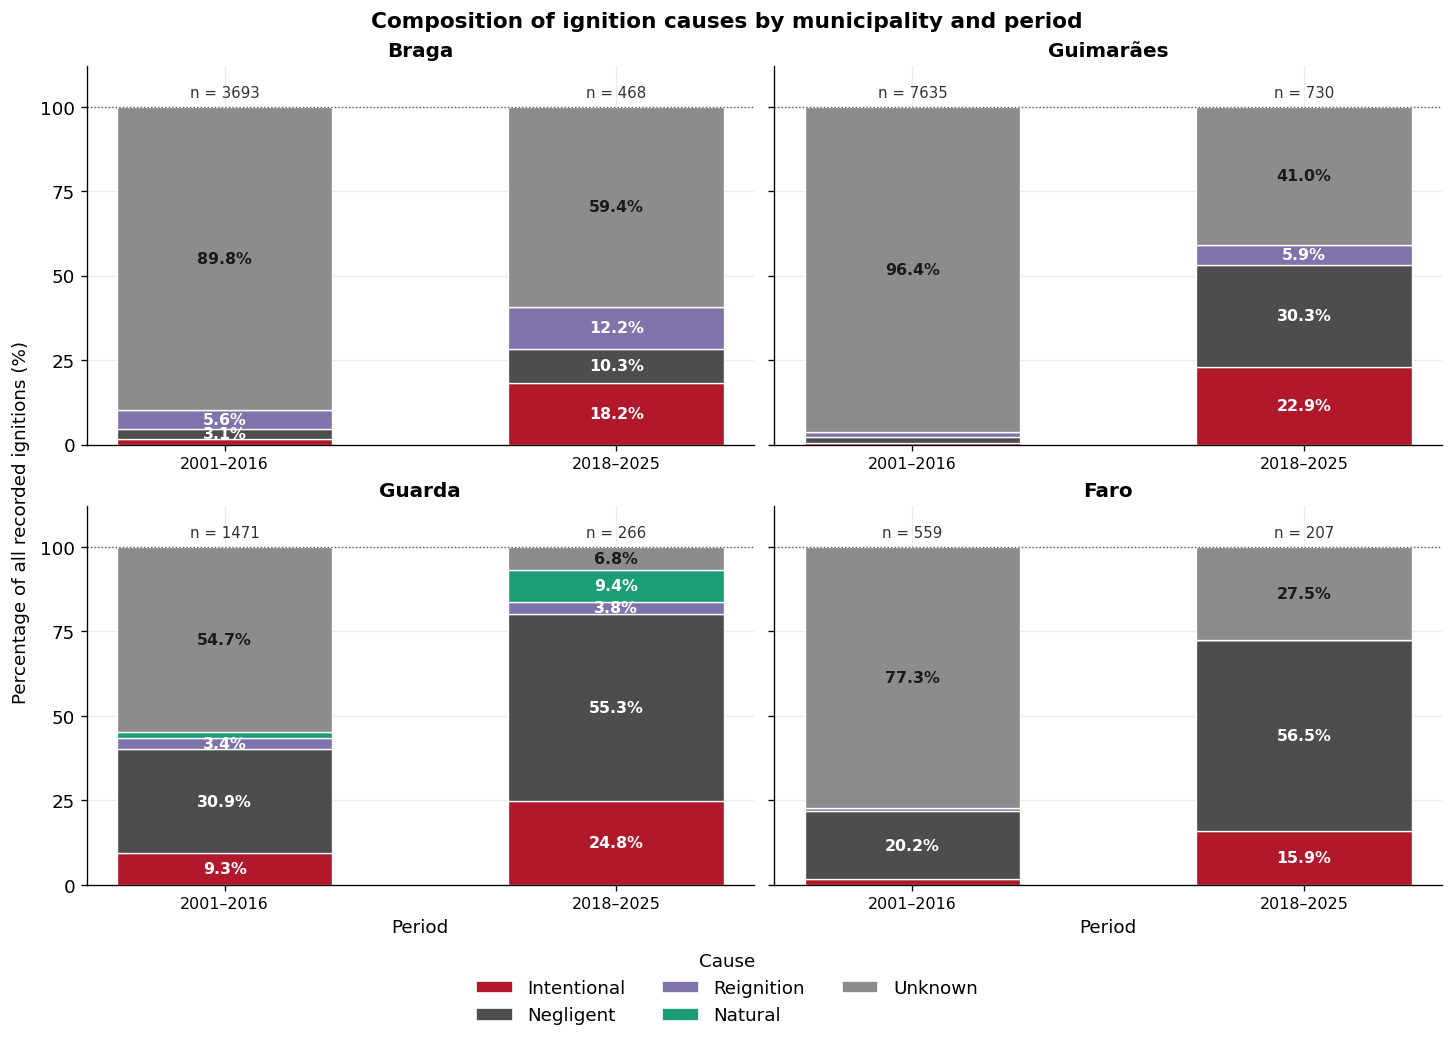

In [100]:
fig, axes = plt.subplots(
    2, 2, figsize=(12, 8.6), sharey=True, constrained_layout=True
)
axes = axes.ravel()

for ax, municipality in zip(axes, MUNICIPALITIES):
    panel_data = cause_counts.loc[
        cause_counts["MUNICIPALITY"] == municipality
    ]

    x_positions = [0, 1]
    bar_width = 0.55

    for period, x_position in zip(COMPARISON_PERIODS, x_positions):

        period_data = (
            panel_data.loc[panel_data["PERIOD"] == period]
            .set_index("CAUSE")
        )

        total_n = int(period_data["TOTAL"].iloc[0])
        bottom = 0.0

        for cause in CAUSE_COMPARISON:
            percentage = float(period_data.loc[cause, "PROPORTION"]) * 100

            ax.bar(
                x_position,
                percentage,
                bottom=bottom,
                width=bar_width,
                color=CAUSE_COLORS[cause],
                edgecolor="white",
                linewidth=0.8,
            )

            if percentage >= CAUSE_LABEL_MIN_PERCENT:
                ax.text(
                    x_position,
                    bottom + percentage / 2,
                    f"{percentage:.1f}%",
                    ha="center",
                    va="center",
                    color=CAUSE_TEXT_COLORS.get(cause, "white"),
                    fontsize=9.5,
                    fontweight="bold",
                )

            bottom += percentage

        if abs(bottom - 100) > 1e-6:
            raise ValueError(
                f"Cause percentages do not sum to 100% for {municipality} "
                f"in {period}."
            )

        ax.text(
            x_position,
            102,
            f"n = {total_n}",
            ha="center",
            va="bottom",
            fontsize=9,
            color="#333333",
        )

    ax.set_title(
        MUNICIPALITY_LABELS[municipality],
        fontsize=12
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        [PERIOD_LABELS[p] for p in COMPARISON_PERIODS],
        fontsize=9.5
    )

    ax.set_ylim(0, 112)
    ax.set_yticks([0, 25, 50, 75, 100])

    ax.axhline(
        100,
        color="#555555",
        linewidth=0.8,
        linestyle=":"
    )

    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)


# Shared legend
legend_handles = [
    Patch(
        facecolor=CAUSE_COLORS[cause],
        edgecolor="white",
        label=CAUSE_LABELS[cause]
    )
    for cause in CAUSE_COMPARISON
]

fig.legend(
    handles=legend_handles,
    title="Cause",
    loc="outside lower center",
    ncol=3,
    frameon=False,
)

# Axis labels
axes[2].set_xlabel("Period", fontsize=11)
axes[3].set_xlabel("Period", fontsize=11)

fig.supylabel(
    "Percentage of all recorded ignitions (%)",
    fontsize=11
)

fig.suptitle(
    "Composition of ignition causes by municipality and period",
    fontsize=13,
    fontweight="bold",
)

plt.show()
plt.close(fig)


**NOTE:** Percentages use all recorded ignitions in each municipality and period as the denominator (n shown above each bar), and every recorded cause category contributes to the stack. The bars therefore describe the full cause composition of recorded ignitions, not only intentional and negligent fires. The 2017 transition year is excluded.

**NOTE:** Percentage labels are shown for segments covering at least 2.5% of a bar. Smaller segments remain visible in the stack, and their exact values are reported in the heatmaps below.


### Cause composition heatmaps

The two heatmaps present the same proportions as the stacked bars in a compact matrix form. The left panel refers to 2001–2016 and the right panel to 2018–2025. Both panels use the same color scale and the same all-cause denominator, and every recorded cause category is shown.


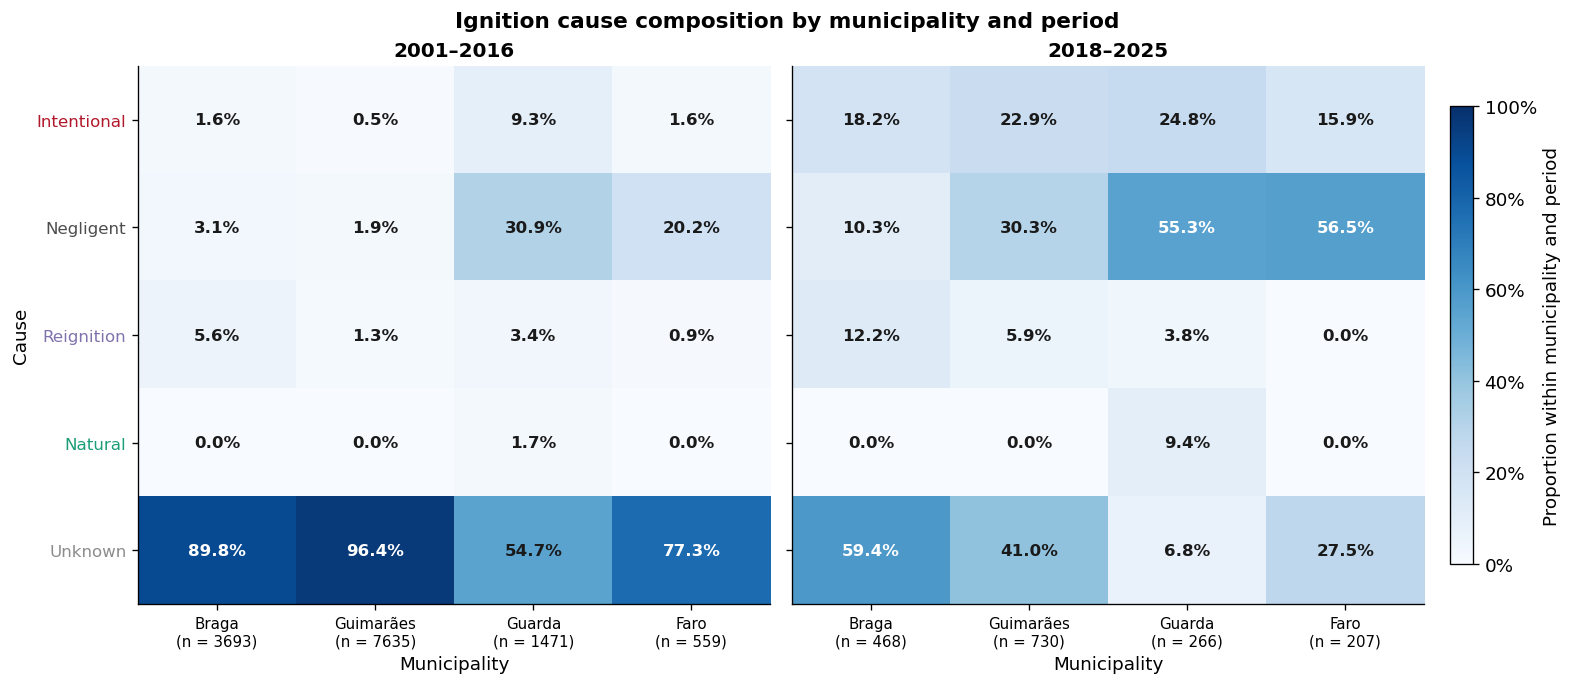

In [101]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 5.6), sharey=True, constrained_layout=True
)

last_image = None
for ax, period in zip(axes, COMPARISON_PERIODS):
    matrix = (
        cause_counts.loc[cause_counts["PERIOD"] == period]
        .pivot(index="CAUSE", columns="MUNICIPALITY", values="PROPORTION")
        .reindex(index=CAUSE_COMPARISON, columns=MUNICIPALITIES)
    )
    if matrix.isna().any().any():
        raise ValueError(f"Missing proportions for period {period}.")

    last_image = ax.imshow(
        matrix.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto"
    )
    totals_for_period = (
        cause_counts.loc[cause_counts["PERIOD"] == period]
        .groupby("MUNICIPALITY")["TOTAL"]
        .first()
        .reindex(MUNICIPALITIES)
    )
    ax.set_xticks(range(len(MUNICIPALITIES)))
    ax.set_xticklabels(
        [
            f"{MUNICIPALITY_LABELS[m]}\n(n = {int(totals_for_period[m])})"
            for m in MUNICIPALITIES
        ],
        fontsize=9,
    )
    ax.set_yticks(range(len(CAUSE_COMPARISON)))
    ax.set_yticklabels([CAUSE_LABELS[c] for c in CAUSE_COMPARISON], fontsize=10)
    for tick_label, cause in zip(ax.get_yticklabels(), CAUSE_COMPARISON):
        tick_label.set_color(CAUSE_COLORS[cause])
    ax.set_title(PERIOD_LABELS[period], fontsize=12)
    ax.set_xlabel("Municipality")
    ax.grid(False)

    for row, cause in enumerate(CAUSE_COMPARISON):
        for column, municipality in enumerate(MUNICIPALITIES):
            value = float(matrix.loc[cause, municipality])
            text_color = "white" if value >= 0.55 else "#1A1A1A"
            ax.text(
                column,
                row,
                f"{value * 100:.1f}%",
                ha="center",
                va="center",
                color=text_color,
                fontsize=10,
                fontweight="bold",
            )

axes[0].set_ylabel("Cause")
fig.colorbar(
    last_image,
    ax=axes.tolist(),
    shrink=0.85,
    pad=0.02,
    format=PercentFormatter(xmax=1.0, decimals=0),
    label="Proportion within municipality and period",
)
fig.suptitle(
    "Ignition cause composition by municipality and period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Both heatmaps use a common color scale from 0% to 100% and the same denominator as the stacked bars: all recorded ignitions in each municipality and period. The sample size for each municipality-period is shown below the municipality labels, and the 2017 transition year is excluded. Every recorded cause category is shown, including `DESCONHECIDA`.


CAUSE TYPE CONCLUSIONS:


## Total Burned Area (ha)

Total burned area (`AREATOTAL_HA`) is the area burned by each ignition record, measured in hectares. The descriptive statistics and the two visualizations below use the `2001-2016` and `2018-2025` comparison records; the 2017 transition year is excluded from these before-and-after comparisons.


In [102]:
# Shared helpers and comparison subset for the quantitative exploratory analysis.
import numpy as np

quantitative_comparison_data = scoped_data.loc[
    scoped_data["PERIOD"].isin(COMPARISON_PERIODS)
].copy()

if (quantitative_comparison_data["PERIOD"].astype(str) == "2017").any():
    raise ValueError("2017 must be excluded from the before-and-after comparisons.")
if set(quantitative_comparison_data["PERIOD"].astype(str)) != set(COMPARISON_PERIODS):
    raise ValueError("The comparison subset contains unexpected periods.")

print(
    f"Quantitative comparison subset: {len(quantitative_comparison_data):,} records "
    f"across {quantitative_comparison_data['MUNICIPALITY'].nunique()} municipalities "
    f"and {quantitative_comparison_data['PERIOD'].nunique()} periods (2017 excluded)."
)


def format_numeric_description(series, variable_name):
    """Return describe(include='all') with readable labels and two-decimal values."""
    summary = series.describe(include="all").to_frame(name=variable_name)
    summary = summary.rename(index={
        "count": "Count",
        "mean": "Mean",
        "std": "Standard deviation",
        "min": "Minimum",
        "25%": "25th percentile",
        "50%": "Median (50%)",
        "75%": "75th percentile",
        "max": "Maximum",
    })
    summary.index.name = "Statistic"
    summary[variable_name] = summary[variable_name].map(
        lambda value: f"{value:,.2f}" if pd.api.types.is_number(value) else value
    )
    return summary


def missingness_summary(series, variable_name):
    """Return the non-missing and missing sample sizes for one variable."""
    total = int(series.shape[0])
    missing = int(series.isna().sum())
    available = total - missing
    return pd.DataFrame(
        {
            "Non-missing observations": [available],
            "Missing observations": [missing],
            "Missing (%)": [f"{100 * missing / total:.2f}"],
        },
        index=pd.Index([variable_name], name="Variable"),
    )


def to_log1p(values):
    """Map non-negative values to log10(1 + x) for display only."""
    return np.log10(1 + np.asarray(values, dtype=float))


def set_log1p_ticks(ax, tick_values, axis="x"):
    """Place original-unit tick labels on a log10(1 + x) axis."""
    tick_values = np.asarray(tick_values, dtype=float)
    positions = np.log10(1 + tick_values)
    labels = [
        f"{value:,.0f}" if value >= 1000 else f"{value:g}"
        for value in tick_values
    ]
    if axis == "x":
        low, high = ax.get_xlim()
        visible = (positions >= low - 1e-9) & (positions <= high + 1e-9)
        ax.set_xticks(positions[visible])
        ax.set_xticklabels([label for label, keep in zip(labels, visible) if keep])
    elif axis == "y":
        low, high = ax.get_ylim()
        visible = (positions >= low - 1e-9) & (positions <= high + 1e-9)
        ax.set_yticks(positions[visible])
        ax.set_yticklabels([label for label, keep in zip(labels, visible) if keep])
    else:
        raise ValueError("axis must be 'x' or 'y'")


Quantitative comparison subset: 15,029 records across 4 municipalities and 2 periods (2017 excluded).


### Descriptive statistics

The table reports `describe(include='all')` for total burned area, followed by the non-missing and missing sample sizes.


In [103]:
burned_area_description = format_numeric_description(
    quantitative_comparison_data["AREATOTAL_HA"], "AREATOTAL_HA"
)
display(burned_area_description)

burned_area_missingness = missingness_summary(
    quantitative_comparison_data["AREATOTAL_HA"], "AREATOTAL_HA"
)
display(burned_area_missingness)


,AREATOTAL_HA
Statistic,
Count,"15,029.00"
Mean,4.76
Standard deviation,105.99
Minimum,0.00
25th percentile,0.01
Median (50%),0.08
75th percentile,0.40
Maximum,"7,802.31"


,Non-missing observations,Missing observations,Missing (%)
Variable,,,
AREATOTAL_HA,15029,0,0.00


### Distribution by period

The two histograms compare the distribution of burned area in `2001-2016` and `2018-2025`, pooling the four municipalities within each period.


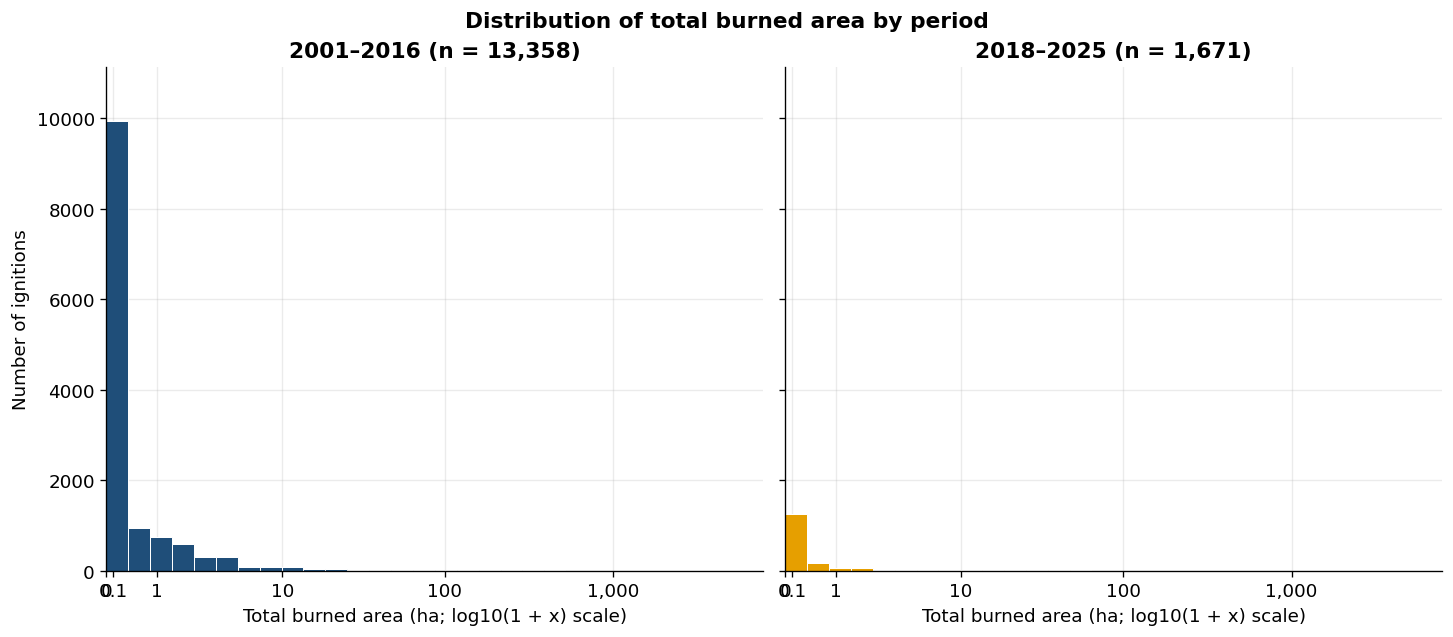

In [104]:
# Histograms of total burned area by period, using identical bins and axes.
burned_area_histogram_data = quantitative_comparison_data.loc[
    :, ["PERIOD", "AREATOTAL_HA"]
].dropna(subset=["AREATOTAL_HA"])

burned_area_transformed = to_log1p(burned_area_histogram_data["AREATOTAL_HA"])
BURNED_AREA_BINS = 30
burned_area_bin_edges = np.linspace(
    0, burned_area_transformed.max(), BURNED_AREA_BINS + 1
)

burned_area_hist_max = max(
    np.histogram(
        burned_area_transformed[
            burned_area_histogram_data["PERIOD"] == period
        ],
        bins=burned_area_bin_edges,
    )[0].max()
    for period in COMPARISON_PERIODS
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.2), sharex=True, sharey=True, constrained_layout=True
)
for ax, period in zip(axes, COMPARISON_PERIODS):
    values = burned_area_transformed[
        burned_area_histogram_data["PERIOD"] == period
    ]
    ax.hist(
        values,
        bins=burned_area_bin_edges,
        color=PERIOD_COLORS[period],
        edgecolor="white",
        linewidth=0.6,
    )
    ax.set_title(f"{PERIOD_LABELS[period]} (n = {len(values):,})")
    ax.set_xlabel("Total burned area (ha; log10(1 + x) scale)")
    ax.set_xlim(burned_area_bin_edges[0], burned_area_bin_edges[-1])
    ax.set_ylim(0, burned_area_hist_max * 1.12)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    set_log1p_ticks(ax, [0, 0.1, 1, 10, 100, 1000, 10000], axis="x")

axes[0].set_ylabel("Number of ignitions")
fig.suptitle(
    "Distribution of total burned area by period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Both panels use 30 equal-width bins on the `log10(1 + burned area)` scale and share the same x- and y-axis limits. The logarithmic display is justified by the strong right skew of burned area (median 0.08 ha; maximum 7,802.31 ha); it is a visualization choice only, and the original hectares are retained. No observations or outliers were removed. The 1,956 records with zero burned area remain in the first bin.


### Comparison between municipalities

The faceted box plots compare the distribution of burned area between periods within each municipality. The same display scale is used in all four panels.


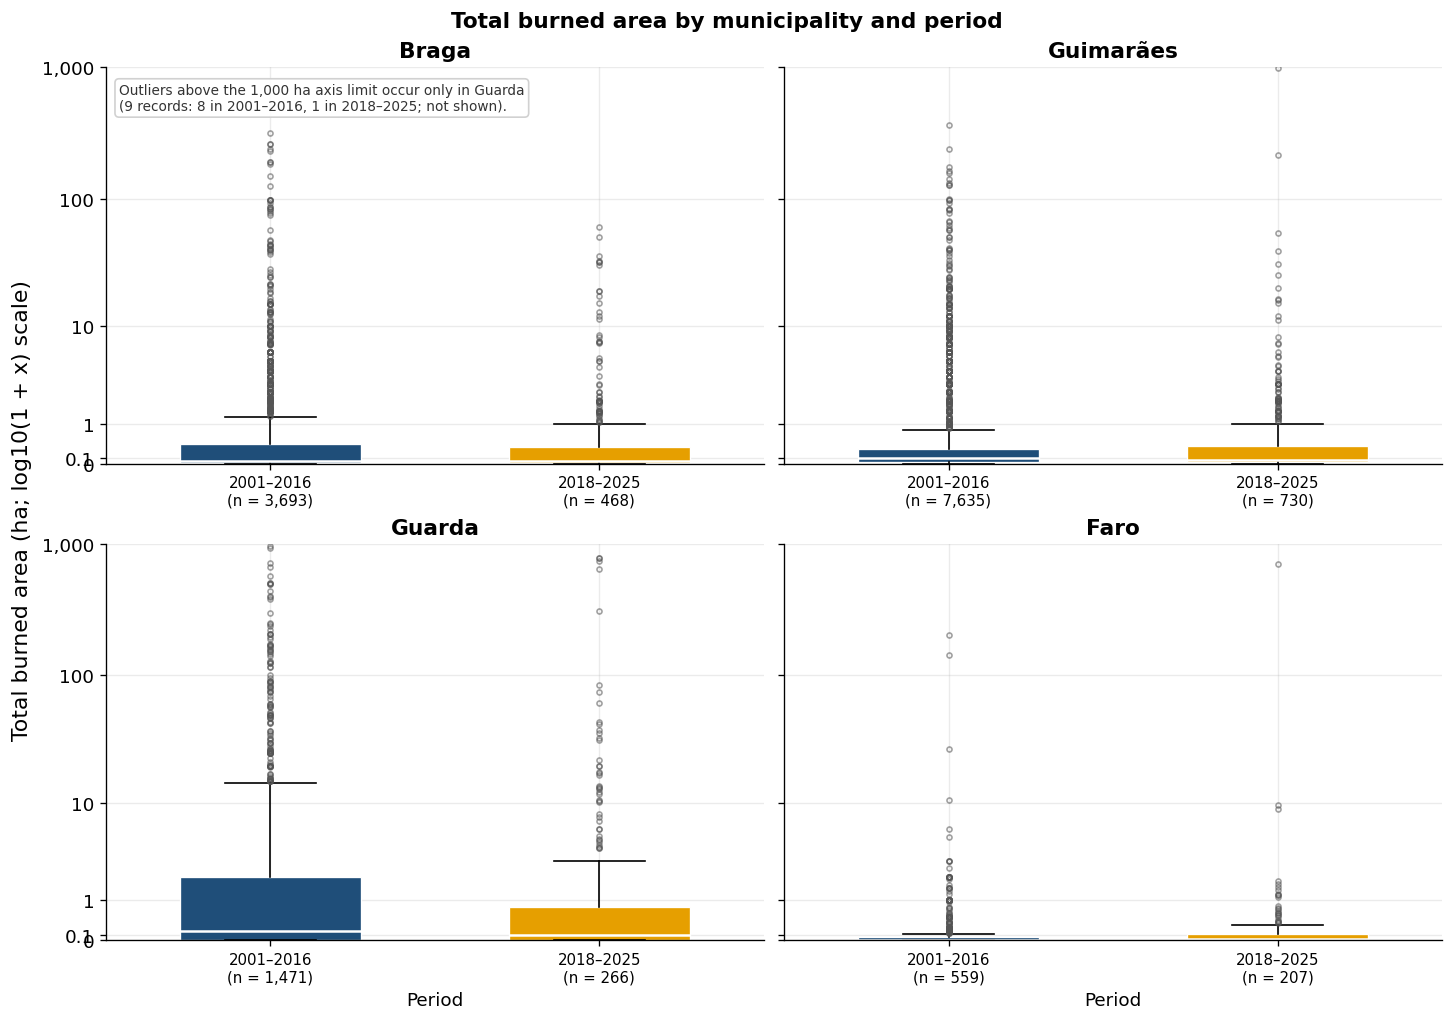

In [105]:
# Faceted box plots of total burned area, one panel per municipality.
BURNED_AREA_DISPLAY_MAX_HA = 1_000

burned_area_box_data = quantitative_comparison_data.loc[
    :, ["MUNICIPALITY", "PERIOD", "AREATOTAL_HA"]
].dropna(subset=["AREATOTAL_HA"])

burned_area_box_transformed = to_log1p(burned_area_box_data["AREATOTAL_HA"])
burned_area_box_ymax = float(to_log1p(BURNED_AREA_DISPLAY_MAX_HA))

burned_area_over_cap = burned_area_box_data.loc[
    burned_area_box_data["AREATOTAL_HA"] > BURNED_AREA_DISPLAY_MAX_HA
]
over_cap_municipalities = sorted(burned_area_over_cap["MUNICIPALITY"].unique())
over_cap_by_period = burned_area_over_cap.groupby("PERIOD", observed=True).size()

if not over_cap_municipalities:
    over_cap_note = "No observations exceed the 1,000 ha axis limit."
elif over_cap_municipalities == ["GUARDA"]:
    over_cap_note = (
        "Outliers above the 1,000 ha axis limit occur only in Guarda\n"
        f"({len(burned_area_over_cap)} records: "
        f"{int(over_cap_by_period.get('2001-2016', 0))} in 2001–2016, "
        f"{int(over_cap_by_period.get('2018-2025', 0))} in 2018–2025; not shown)."
    )
else:
    over_cap_note = (
        "Outliers above the 1,000 ha axis limit occur in "
        + ", ".join(MUNICIPALITY_LABELS[m] for m in over_cap_municipalities)
        + f" ({len(burned_area_over_cap)} records; not shown)."
    )

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8.4), sharey=True, constrained_layout=True
)
axes = axes.ravel()

for ax, municipality in zip(axes, MUNICIPALITIES):
    panel = burned_area_box_data.loc[
        burned_area_box_data["MUNICIPALITY"] == municipality
    ]
    values = [
        to_log1p(panel.loc[panel["PERIOD"] == period, "AREATOTAL_HA"])
        for period in COMPARISON_PERIODS
    ]

    boxplot = ax.boxplot(
        values,
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=True,
        whis=1.5,
        medianprops={"color": "white", "linewidth": 1.5},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "none",
            "markeredgecolor": "#555555",
            "alpha": 0.55,
        },
    )
    for patch, period in zip(boxplot["boxes"], COMPARISON_PERIODS):
        patch.set_facecolor(PERIOD_COLORS[period])
        patch.set_edgecolor("white")
        patch.set_linewidth(0.8)

    ax.set_title(MUNICIPALITY_LABELS[municipality])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        [
            f"{PERIOD_LABELS[period]}\n(n = {len(group_values):,})"
            for period, group_values in zip(COMPARISON_PERIODS, values)
        ],
        fontsize=9,
    )
    ax.set_ylim(0, burned_area_box_ymax)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    set_log1p_ticks(ax, [0, 0.1, 1, 10, 100, 1000], axis="y")

    if municipality == "BRAGA":
        ax.text(
            0.02,
            0.96,
            over_cap_note,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=8.2,
            color="#333333",
            bbox={
                "boxstyle": "round,pad=0.3",
                "facecolor": "white",
                "edgecolor": "#CCCCCC",
                "alpha": 0.9,
            },
        )

for ax in axes[2:]:
    ax.set_xlabel("Period")

fig.supylabel("Total burned area (ha; log10(1 + x) scale)")
fig.suptitle(
    "Total burned area by municipality and period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Box plots use the same `log10(1 + burned area)` display scale across all panels, with whiskers at 1.5 × IQR on the transformed scale and all outliers shown within the plotted range. The y-axis is capped at 1,000 ha; the 9 Guarda observations above that cap (8 in 2001–2016 and 1 in 2018–2025) lie outside the displayed range and are therefore not drawn. All other outliers remain visible, and sample sizes are reported below each period label. The transformation and the cap are visual choices only; the underlying values are unchanged.


TOTAL BURNED AREA CONCLUSIONS:


## Intervention Time (minutes)

Intervention time (`INTERVENTION_TIME_MINUTES`) is the elapsed time between the alert timestamp and the first intervention timestamp, measured in minutes. Missing timestamps produce missing intervention times; these values are not imputed or replaced with zero, and their number is reported explicitly. The descriptive statistics and plots use the `2001-2016` and `2018-2025` comparison records, excluding 2017.


### Descriptive statistics

The table reports `describe(include='all')` for intervention time, followed by the overall and municipality-period coverage of non-missing observations.


In [106]:
intervention_description = format_numeric_description(
    quantitative_comparison_data["INTERVENTION_TIME_MINUTES"],
    "INTERVENTION_TIME_MINUTES",
)
display(intervention_description)

intervention_missingness = missingness_summary(
    quantitative_comparison_data["INTERVENTION_TIME_MINUTES"],
    "INTERVENTION_TIME_MINUTES",
)
display(intervention_missingness)

intervention_coverage = (
    quantitative_comparison_data
    .groupby(["MUNICIPALITY", "PERIOD"], observed=True)["INTERVENTION_TIME_MINUTES"]
    .agg(Non_missing="count", Total="size")
    .reindex(
        pd.MultiIndex.from_product(
            [MUNICIPALITIES, COMPARISON_PERIODS],
            names=["MUNICIPALITY", "PERIOD"],
        )
    )
    .reset_index()
)
intervention_coverage["Missing"] = (
    intervention_coverage["Total"] - intervention_coverage["Non_missing"]
)
intervention_coverage["Missing (%)"] = (
    100 * intervention_coverage["Missing"] / intervention_coverage["Total"]
).round(2)
display(intervention_coverage)


,INTERVENTION_TIME_MINUTES
Statistic,
Count,"6,699.00"
Mean,12.43
Standard deviation,9.45
Minimum,0.00
25th percentile,7.00
Median (50%),11.00
75th percentile,15.00
Maximum,265.00


,Non-missing observations,Missing observations,Missing (%)
Variable,,,
INTERVENTION_TIME_MINUTES,6699,8330,55.43


,MUNICIPALITY,PERIOD,Non_missing,Total,Missing,Missing (%)
0,BRAGA,2001-2016,1485,3693,2208,59.79
1,BRAGA,2018-2025,465,468,3,0.64
2,GUIMARAES,2001-2016,2666,7635,4969,65.08
3,GUIMARAES,2018-2025,729,730,1,0.14
4,GUARDA,2001-2016,584,1471,887,60.30
5,GUARDA,2018-2025,262,266,4,1.50
6,FARO,2001-2016,301,559,258,46.15
7,FARO,2018-2025,207,207,0,0.00


### Distribution by period

The two histograms compare the distribution of intervention time in `2001-2016` and `2018-2025`, pooling the four municipalities within each period.


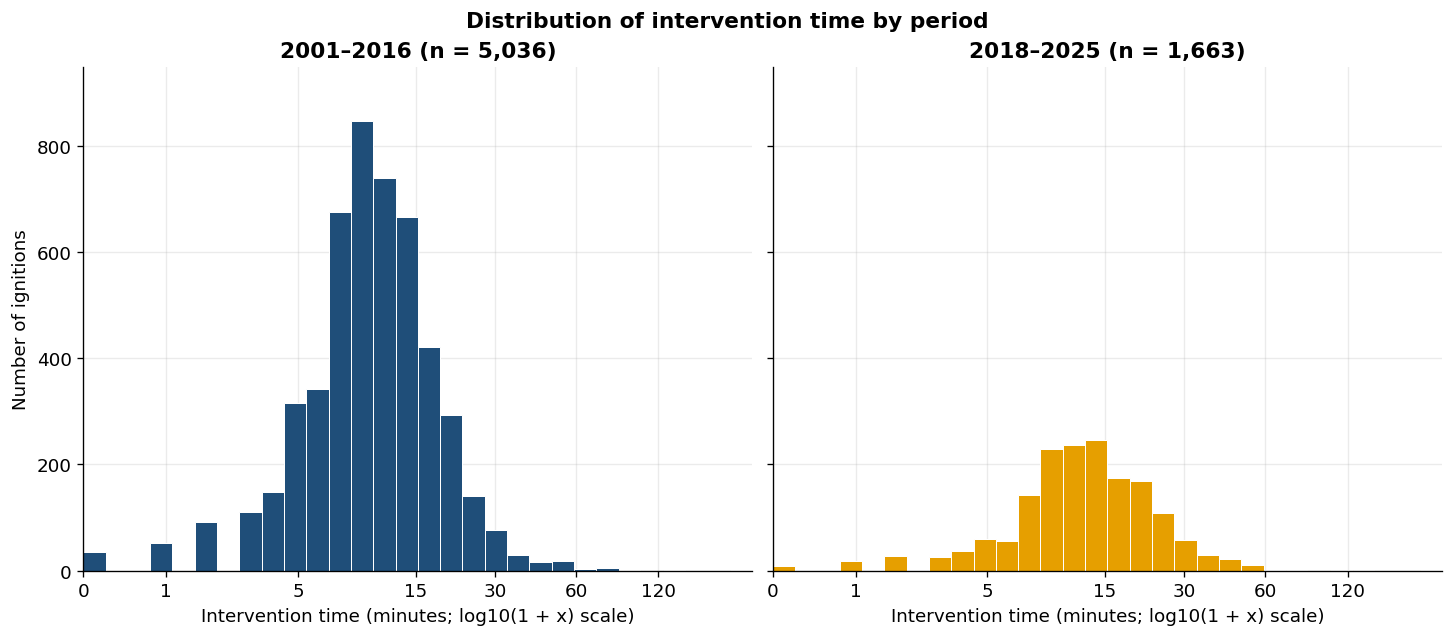

In [107]:
# Histograms of intervention time by period, using identical bins and axes.
intervention_histogram_data = quantitative_comparison_data.loc[
    :, ["PERIOD", "INTERVENTION_TIME_MINUTES"]
].dropna(subset=["INTERVENTION_TIME_MINUTES"])

intervention_transformed = to_log1p(
    intervention_histogram_data["INTERVENTION_TIME_MINUTES"]
)
INTERVENTION_BINS = 30
intervention_bin_edges = np.linspace(
    0, intervention_transformed.max(), INTERVENTION_BINS + 1
)

intervention_hist_max = max(
    np.histogram(
        intervention_transformed[
            intervention_histogram_data["PERIOD"] == period
        ],
        bins=intervention_bin_edges,
    )[0].max()
    for period in COMPARISON_PERIODS
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.2), sharex=True, sharey=True, constrained_layout=True
)
for ax, period in zip(axes, COMPARISON_PERIODS):
    values = intervention_transformed[
        intervention_histogram_data["PERIOD"] == period
    ]
    ax.hist(
        values,
        bins=intervention_bin_edges,
        color=PERIOD_COLORS[period],
        edgecolor="white",
        linewidth=0.6,
    )
    ax.set_title(f"{PERIOD_LABELS[period]} (n = {len(values):,})")
    ax.set_xlabel("Intervention time (minutes; log10(1 + x) scale)")
    ax.set_xlim(intervention_bin_edges[0], intervention_bin_edges[-1])
    ax.set_ylim(0, intervention_hist_max * 1.12)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    set_log1p_ticks(ax, [0, 1, 5, 15, 30, 60, 120, 300, 600], axis="x")

axes[0].set_ylabel("Number of ignitions")
fig.suptitle(
    "Distribution of intervention time by period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Both panels use 30 equal-width bins on the `log10(1 + minutes)` scale and share the same x- and y-axis limits. The logarithmic display is used because intervention times are right-skewed (median 11 minutes; maximum 265 minutes). Only the 6,699 non-missing observations are plotted; the 8,330 missing intervention times (55.43% of the 15,029 comparison records) are excluded and are not imputed or replaced with zero. The 44 zero-minute records remain in the first bin.


### Comparison between municipalities

The faceted box plots compare intervention time between periods within each municipality. The same display scale is used in all four panels, and sample sizes are reported below each period label.


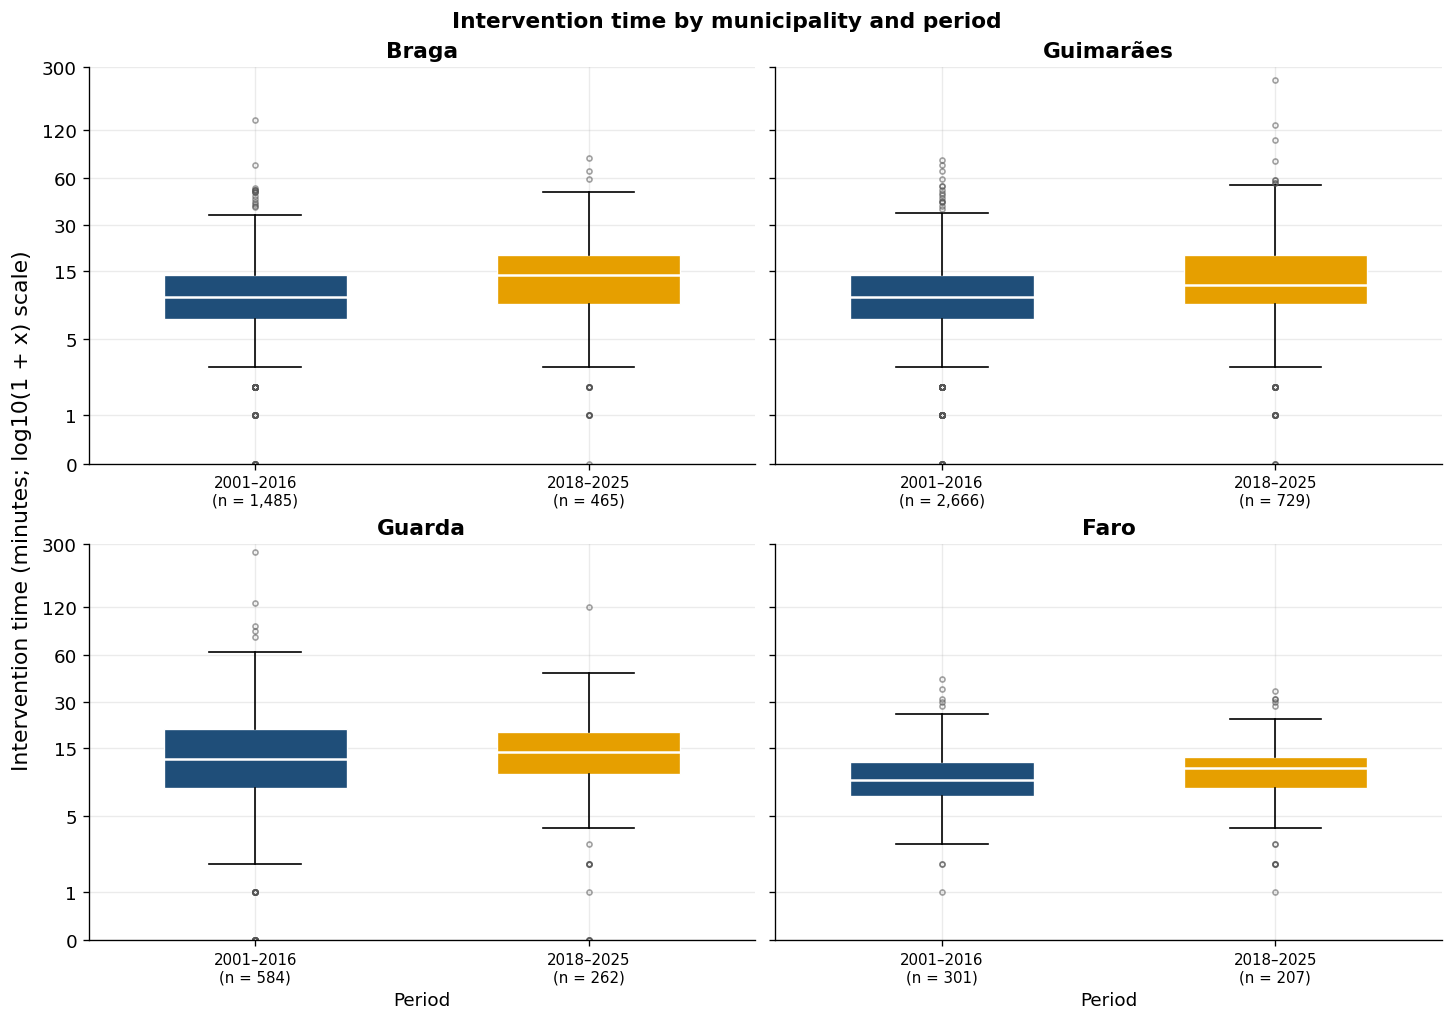

In [108]:
# Faceted box plots of intervention time, one panel per municipality.
INTERVENTION_DISPLAY_MAX_MINUTES = 300

intervention_box_data = quantitative_comparison_data.loc[
    :, ["MUNICIPALITY", "PERIOD", "INTERVENTION_TIME_MINUTES"]
].dropna(subset=["INTERVENTION_TIME_MINUTES"])

intervention_box_transformed = to_log1p(
    intervention_box_data["INTERVENTION_TIME_MINUTES"]
)
intervention_box_ymax = float(
    to_log1p(INTERVENTION_DISPLAY_MAX_MINUTES)
)

if intervention_box_data["INTERVENTION_TIME_MINUTES"].max() > INTERVENTION_DISPLAY_MAX_MINUTES:
    raise ValueError(
        "At least one observed intervention time exceeds the 300-minute display limit."
    )

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8.4), sharey=True, constrained_layout=True
)
axes = axes.ravel()

for ax, municipality in zip(axes, MUNICIPALITIES):
    panel = intervention_box_data.loc[
        intervention_box_data["MUNICIPALITY"] == municipality
    ]
    values = [
        to_log1p(panel.loc[panel["PERIOD"] == period, "INTERVENTION_TIME_MINUTES"])
        for period in COMPARISON_PERIODS
    ]

    boxplot = ax.boxplot(
        values,
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=True,
        whis=1.5,
        medianprops={"color": "white", "linewidth": 1.5},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "none",
            "markeredgecolor": "#555555",
            "alpha": 0.55,
        },
    )
    for patch, period in zip(boxplot["boxes"], COMPARISON_PERIODS):
        patch.set_facecolor(PERIOD_COLORS[period])
        patch.set_edgecolor("white")
        patch.set_linewidth(0.8)

    ax.set_title(MUNICIPALITY_LABELS[municipality])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        [
            f"{PERIOD_LABELS[period]}\n(n = {len(group_values):,})"
            for period, group_values in zip(COMPARISON_PERIODS, values)
        ],
        fontsize=9,
    )
    ax.set_ylim(0, intervention_box_ymax)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    set_log1p_ticks(ax, [0, 1, 5, 15, 30, 60, 120, 300], axis="y")

for ax in axes[2:]:
    ax.set_xlabel("Period")

fig.supylabel("Intervention time (minutes; log10(1 + x) scale)")
fig.suptitle(
    "Intervention time by municipality and period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Box plots use the same `log10(1 + minutes)` display scale, with whiskers at 1.5 × IQR on the transformed scale and all outliers shown. The y-axis is capped at 300 minutes; the maximum observed value is 265 minutes, so no valid non-missing observations are excluded. Sample sizes below each period label are non-missing observations. Missingness differs substantially by municipality and period (see the coverage table above) and is not assumed to be random.


INTERVENTION TIME CONCLUSIONS:


## Duration (hours)

Duration (`DURACAO_HORAS`) is the time between the alert and extinction timestamps, measured in hours. The descriptive statistics and plots use the `2001-2016` and `2018-2025` comparison records, excluding 2017; the single missing duration is reported and excluded from the visualizations.


### Descriptive statistics

The table reports `describe(include='all')` for fire duration, followed by the non-missing and missing sample sizes.


In [109]:
duration_description = format_numeric_description(
    quantitative_comparison_data["DURACAO_HORAS"], "DURACAO_HORAS"
)
display(duration_description)

duration_missingness = missingness_summary(
    quantitative_comparison_data["DURACAO_HORAS"], "DURACAO_HORAS"
)
display(duration_missingness)


,DURACAO_HORAS
Statistic,
Count,"15,028.00"
Mean,2.00
Standard deviation,7.61
Minimum,0.00
25th percentile,0.67
Median (50%),1.17
75th percentile,1.92
Maximum,748.95


,Non-missing observations,Missing observations,Missing (%)
Variable,,,
DURACAO_HORAS,15028,1,0.01


### Distribution by period

The two histograms compare the distribution of fire duration in `2001-2016` and `2018-2025`, pooling the four municipalities within each period.


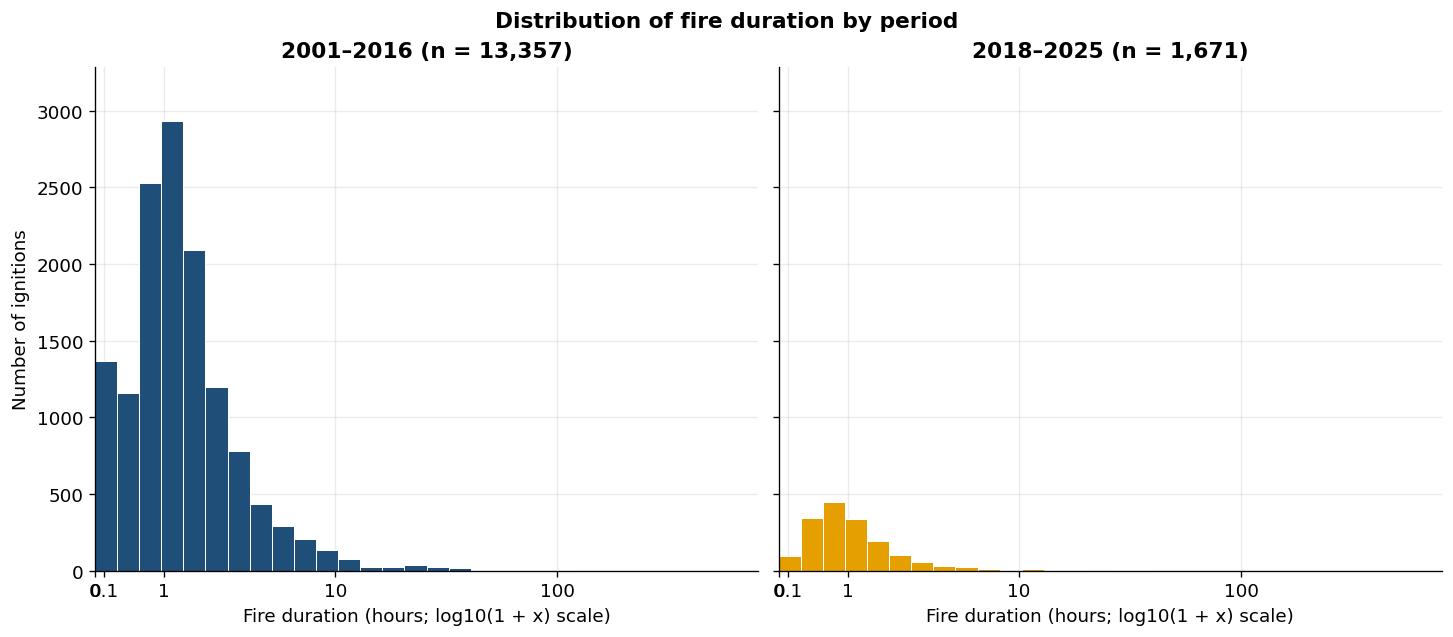

In [110]:
# Histograms of fire duration by period, using identical bins and axes.
duration_histogram_data = quantitative_comparison_data.loc[
    :, ["PERIOD", "DURACAO_HORAS"]
].dropna(subset=["DURACAO_HORAS"])

duration_transformed = to_log1p(duration_histogram_data["DURACAO_HORAS"])
DURATION_BINS = 30
duration_bin_edges = np.linspace(
    0, duration_transformed.max(), DURATION_BINS + 1
)

duration_hist_max = max(
    np.histogram(
        duration_transformed[
            duration_histogram_data["PERIOD"] == period
        ],
        bins=duration_bin_edges,
    )[0].max()
    for period in COMPARISON_PERIODS
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.2), sharex=True, sharey=True, constrained_layout=True
)
for ax, period in zip(axes, COMPARISON_PERIODS):
    values = duration_transformed[
        duration_histogram_data["PERIOD"] == period
    ]
    ax.hist(
        values,
        bins=duration_bin_edges,
        color=PERIOD_COLORS[period],
        edgecolor="white",
        linewidth=0.6,
    )
    ax.set_title(f"{PERIOD_LABELS[period]} (n = {len(values):,})")
    ax.set_xlabel("Fire duration (hours; log10(1 + x) scale)")
    ax.set_xlim(duration_bin_edges[0], duration_bin_edges[-1])
    ax.set_ylim(0, duration_hist_max * 1.12)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    set_log1p_ticks(ax, [0, 0.1, 1, 10, 100, 1000], axis="x")

axes[0].set_ylabel("Number of ignitions")
fig.suptitle(
    "Distribution of fire duration by period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Both panels use 30 equal-width bins on the `log10(1 + hours)` scale and share the same x- and y-axis limits. The logarithmic display is justified by the strong right skew of fire duration (median 1.17 hours; maximum 748.95 hours). The single missing duration (Guarda, 2001–2016) is excluded from the plot; the 44 zero-duration records remain in the first bin. No observations or outliers were removed.


### Comparison between municipalities

The faceted box plots compare the distribution of fire duration between periods within each municipality. The same display scale is used in all four panels, sample sizes are reported below each period label, and all outliers are shown.


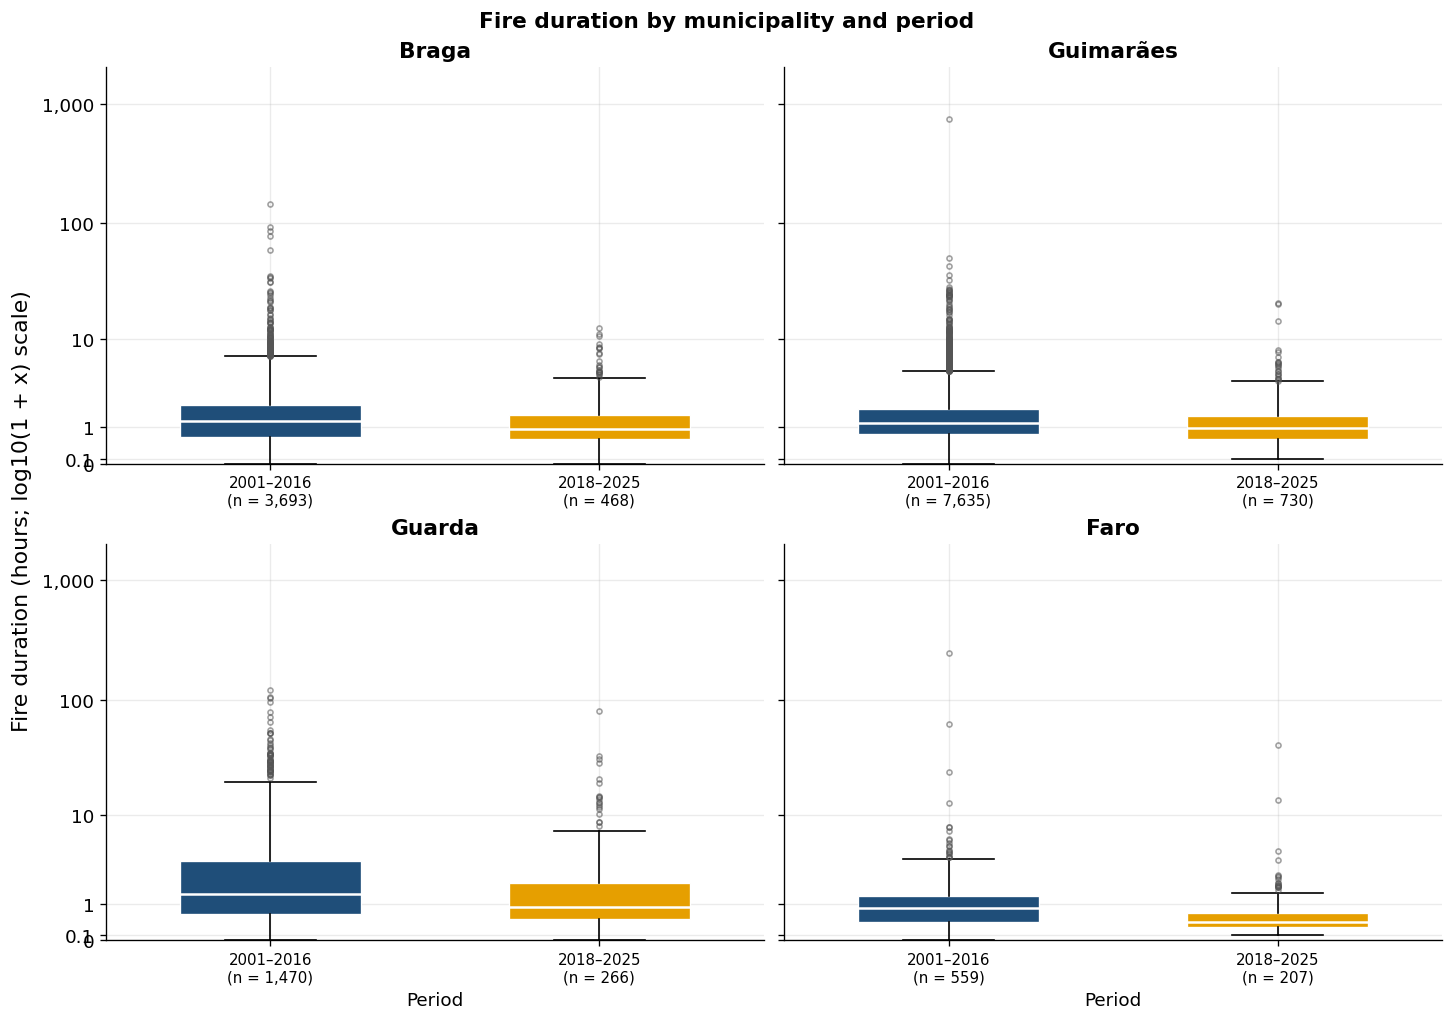

In [111]:
# Faceted box plots of fire duration, one panel per municipality.
duration_box_data = quantitative_comparison_data.loc[
    :, ["MUNICIPALITY", "PERIOD", "DURACAO_HORAS"]
].dropna(subset=["DURACAO_HORAS"])

duration_box_transformed = to_log1p(duration_box_data["DURACAO_HORAS"])
duration_box_max = duration_box_transformed.max()

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8.4), sharey=True, constrained_layout=True
)
axes = axes.ravel()

for ax, municipality in zip(axes, MUNICIPALITIES):
    panel = duration_box_data.loc[
        duration_box_data["MUNICIPALITY"] == municipality
    ]
    values = [
        to_log1p(panel.loc[panel["PERIOD"] == period, "DURACAO_HORAS"])
        for period in COMPARISON_PERIODS
    ]

    boxplot = ax.boxplot(
        values,
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=True,
        whis=1.5,
        medianprops={"color": "white", "linewidth": 1.5},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "none",
            "markeredgecolor": "#555555",
            "alpha": 0.55,
        },
    )
    for patch, period in zip(boxplot["boxes"], COMPARISON_PERIODS):
        patch.set_facecolor(PERIOD_COLORS[period])
        patch.set_edgecolor("white")
        patch.set_linewidth(0.8)

    ax.set_title(MUNICIPALITY_LABELS[municipality])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        [
            f"{PERIOD_LABELS[period]}\n(n = {len(group_values):,})"
            for period, group_values in zip(COMPARISON_PERIODS, values)
        ],
        fontsize=9,
    )
    ax.set_ylim(0, duration_box_max * 1.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    set_log1p_ticks(ax, [0, 0.1, 1, 10, 100, 1000], axis="y")

for ax in axes[2:]:
    ax.set_xlabel("Period")

fig.supylabel("Fire duration (hours; log10(1 + x) scale)")
fig.suptitle(
    "Fire duration by municipality and period",
    fontsize=13,
    fontweight="bold",
)
plt.show()
plt.close(fig)


**NOTE:** Box plots use the same `log10(1 + hours)` display scale across all panels, with whiskers at 1.5 × IQR on the transformed scale and all outliers shown. Sample sizes below each period label are non-missing observations. All non-missing duration records are included; the single missing duration (Guarda, 2001–2016) is excluded. The transformation is visual only, and the underlying values are unchanged.


DURATION CONCLUSIONS:


## Ignition Density (ignitions/km²/year)

Ignition density is an aggregated measure at the municipality-year level: the annual number of ignitions divided by the municipality's geographical area. It is constructed in a separate municipality-year table and is not merged into the row-level canonical dataset. Unlike the previous comparisons, this analysis includes all years from 2001 through 2025, including the 2017 transition year.


### Derived municipality-year table

The table below aggregates annual ignition counts by municipality and year, attaches the existing municipality areas, and calculates annual density as `IGNITIONS / AREA_KM2`. It uses the full ignition population, not only intentional and negligent causes. The existing `calculate_ignition_density` helper is not used here because it divides by the number of years and therefore returns a multi-year average; the annual table below divides each municipality-year count by area only.


In [112]:
# Derived municipality-year table for annual ignition density.
expected_years = list(range(2001, 2026))
observed_years = set(
    scoped_data["ANALYSIS_YEAR"].dropna().astype(int).unique()
)
if observed_years != set(expected_years):
    raise ValueError("The canonical data do not cover every year from 2001 to 2025.")

annual_ignition_counts = (
    scoped_data
    .groupby(["MUNICIPALITY", "ANALYSIS_YEAR"], observed=True)
    .size()
    .rename("IGNITIONS")
    .reset_index()
)

expected_index = pd.MultiIndex.from_product(
    [MUNICIPALITIES, expected_years],
    names=["MUNICIPALITY", "ANALYSIS_YEAR"],
)
annual_ignition_counts = (
    annual_ignition_counts
    .set_index(["MUNICIPALITY", "ANALYSIS_YEAR"])
    .reindex(expected_index)
)
if annual_ignition_counts["IGNITIONS"].isna().any():
    missing_units = annual_ignition_counts.index[
        annual_ignition_counts["IGNITIONS"].isna()
    ].tolist()
    raise ValueError(
        "Missing municipality-year units were found and were not imputed as zero: "
        f"{missing_units}"
    )
annual_ignition_counts = annual_ignition_counts.reset_index()

annual_ignition_counts["AREA_KM2"] = (
    annual_ignition_counts["MUNICIPALITY"].map(MUNICIPALITIES_AREA_KM2)
)
if annual_ignition_counts["AREA_KM2"].isna().any():
    raise ValueError("At least one municipality has no area in MUNICIPALITIES_AREA_KM2.")

annual_ignition_counts["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"] = (
    annual_ignition_counts["IGNITIONS"] / annual_ignition_counts["AREA_KM2"]
)

if len(annual_ignition_counts) != len(MUNICIPALITIES) * len(expected_years):
    raise ValueError("The annual density table does not have one row per municipality-year.")
if (annual_ignition_counts["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"] < 0).any():
    raise ValueError("Negative ignition density values were found.")

# Independent spot checks of the aggregation and area division.
density_spot_checks = [
    ("BRAGA", 2001),
    ("FARO", 2017),
    ("GUARDA", 2025),
    ("GUIMARAES", 2010),
]
for municipality, year in density_spot_checks:
    expected_density = (
        ((scoped_data["MUNICIPALITY"] == municipality) & (scoped_data["ANALYSIS_YEAR"] == year)).sum()
        / MUNICIPALITIES_AREA_KM2[municipality]
    )
    actual_density = float(
        annual_ignition_counts.loc[
            (annual_ignition_counts["MUNICIPALITY"] == municipality)
            & (annual_ignition_counts["ANALYSIS_YEAR"] == year),
            "IGNITION_DENSITY_IGNITIONS_KM2_YEAR",
        ].iloc[0]
    )
    if not np.isclose(actual_density, expected_density):
        raise ValueError(
            f"Density spot check failed for {municipality} in {year}: "
            f"{actual_density} != {expected_density}."
        )

print(
    f"Annual density table: {len(annual_ignition_counts):,} municipality-year rows "
    f"for {len(MUNICIPALITIES)} municipalities and {len(expected_years)} years."
)
print("Independent density spot checks passed for: " + ", ".join(
    f"{municipality} {year}" for municipality, year in density_spot_checks
) + ".")
display(annual_ignition_counts.head(8).round(2))


Annual density table: 100 municipality-year rows for 4 municipalities and 25 years.
Independent density spot checks passed for: BRAGA 2001, FARO 2017, GUARDA 2025, GUIMARAES 2010.


,MUNICIPALITY,ANALYSIS_YEAR,IGNITIONS,AREA_KM2,IGNITION_DENSITY_IGNITIONS_KM2_YEAR
0,BRAGA,2001,285,183,1.56
1,BRAGA,2002,279,183,1.52
2,BRAGA,2003,381,183,2.08
3,BRAGA,2004,253,183,1.38
4,BRAGA,2005,406,183,2.22
5,BRAGA,2006,330,183,1.80
6,BRAGA,2007,216,183,1.18
7,BRAGA,2008,83,183,0.45


### Descriptive statistics

The table reports `describe(include='all')` for the derived annual ignition-density variable, followed by the non-missing and missing sample sizes. The observational unit is the municipality-year.


In [113]:
density_description = format_numeric_description(
    annual_ignition_counts["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"],
    "IGNITION_DENSITY_IGNITIONS_KM2_YEAR",
)
display(density_description)

density_missingness = missingness_summary(
    annual_ignition_counts["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"],
    "IGNITION_DENSITY_IGNITIONS_KM2_YEAR",
)
display(density_missingness)


,IGNITION_DENSITY_IGNITIONS_KM2_YEAR
Statistic,
Count,100.00
Mean,0.66
Standard deviation,0.86
Minimum,0.03
25th percentile,0.12
Median (50%),0.23
75th percentile,1.00
Maximum,3.94


,Non-missing observations,Missing observations,Missing (%)
Variable,,,
IGNITION_DENSITY_IGNITIONS_KM2_YEAR,100,0,0.00


### Annual evolution

The line plot shows the annual evolution of ignition density for each municipality from 2001 through 2025. A grey band marks 2017 as the transition year.


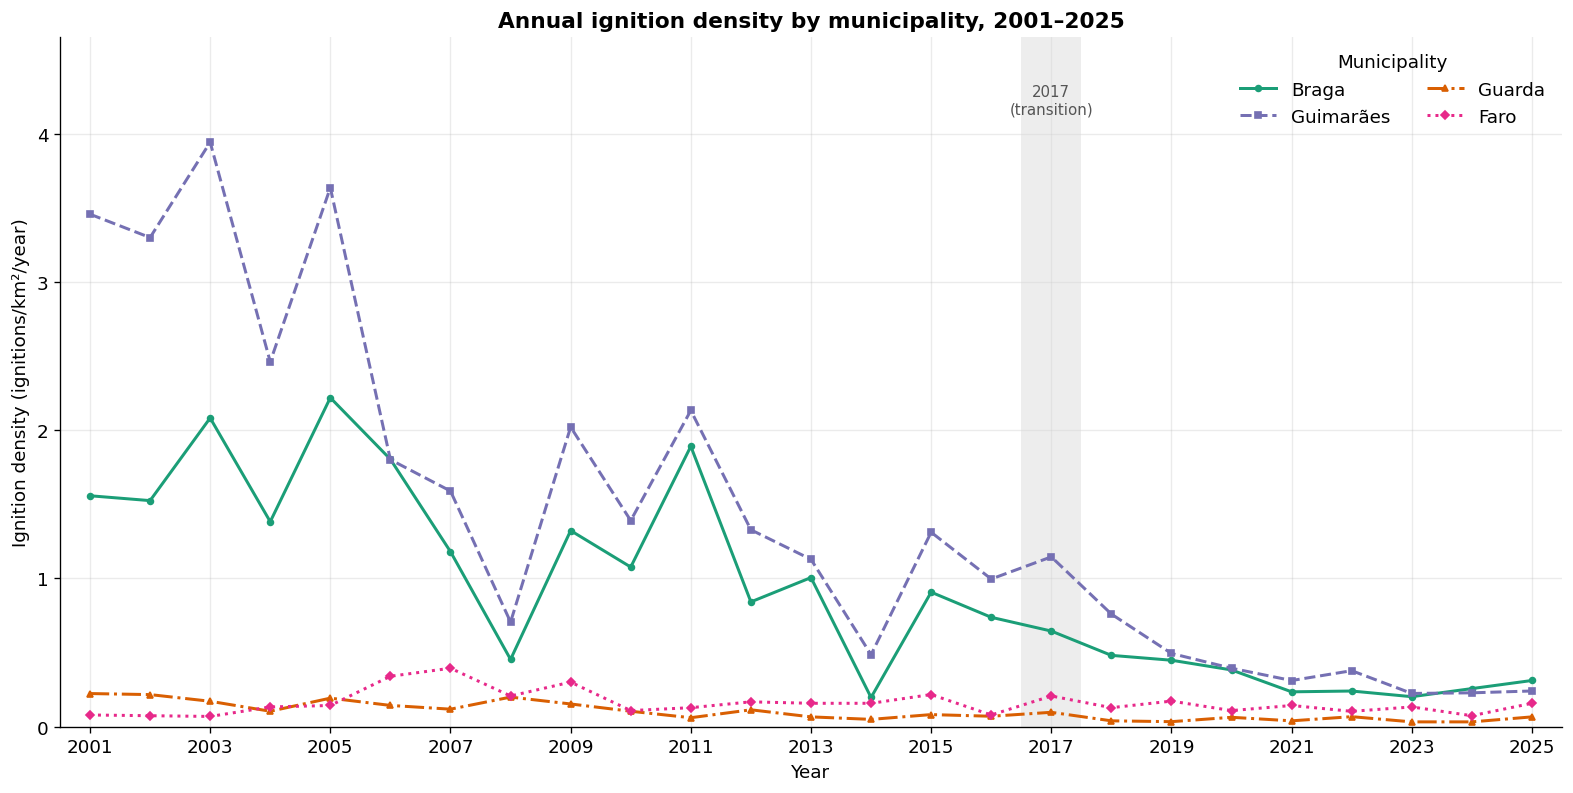

In [114]:
# Annual ignition density by municipality, including 2017.
density_max = annual_ignition_counts["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"].max()

fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)
for municipality in MUNICIPALITIES:
    series = annual_ignition_counts.loc[
        annual_ignition_counts["MUNICIPALITY"] == municipality
    ].sort_values("ANALYSIS_YEAR")
    ax.plot(
        series["ANALYSIS_YEAR"],
        series["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"],
        color=MUNICIPALITY_COLORS[municipality],
        linestyle=MUNICIPALITY_LINESTYLES[municipality],
        marker=MUNICIPALITY_MARKERS[municipality],
        markersize=3.5,
        linewidth=1.8,
        label=MUNICIPALITY_LABELS[municipality],
    )

ax.axvspan(2016.5, 2017.5, color="#D9D9D9", alpha=0.45, linewidth=0)
ax.text(
    2017,
    density_max * 1.10,
    "2017\n(transition)",
    ha="center",
    va="top",
    fontsize=9,
    color="#555555",
)
ax.set_xticks(list(range(2001, 2026, 2)))
ax.set_xlim(2000.5, 2025.5)
ax.set_ylim(0, density_max * 1.18)
ax.set_xlabel("Year")
ax.set_ylabel("Ignition density (ignitions/km²/year)")
ax.set_title("Annual ignition density by municipality, 2001–2025")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Municipality", loc="upper right", ncol=2)
plt.show()
plt.close(fig)


**NOTE:** Density is calculated from the derived municipality-year table as annual ignitions divided by the fixed municipality area (Braga 183 km², Guimarães 241 km², Guarda 712 km², Faro 203 km²). The table has one row per municipality-year (100 rows), and every unit contains records, so no zero imputation was needed. Counts use the full ignition population, not only intentional and negligent causes. The 2017 transition year is included in this plot and marked by the grey band; the plotted values are annual densities, not multi-year averages.


IGNITION DENSITY CONCLUSIONS:
